# 🏠 Real Estate Investment Advisor
### Predicting Property Profitability & Future Value
**Author:** Vipsa | Labmentix Internship, Business/Data Analyst batch

**Business problem:** Investors need two answers before buying:
1. Is this property a **Good Investment**?
2. What will it be worth **after 5 years**?

**Dataset:** india_housing_prices.csv (250,000 properties, 23 columns, 20 states, 42 cities)

**Approach:** Clean → Preprocess → Feature engineering → EDA (20 questions) → Correlation → Rule-based investment logic → Streamlit app

In [1]:
# Libraries = ready-made toolboxes
import pandas as pd              # tables
import numpy as np               # maths
import matplotlib.pyplot as plt  # basic charts
import seaborn as sns            # nicer charts
import plotly.express as px      # interactive charts
import warnings
warnings.filterwarnings("ignore")  # hide harmless warning messages

In [2]:
pd.set_option("display.max_columns", None)  # show all columns
pd.set_option("display.float_format", "{:,.2f}".format)  # 2 decimals, commas

# One colour theme for every chart (navy, teal, gold, coral, slate)
PALETTE = ["#1F3B57", "#2A9D8F", "#E9C46A", "#E76F51", "#8D99AE"]
sns.set_theme(style="whitegrid", palette=PALETTE)
plt.rcParams["figure.figsize"] = (10, 5)

**Data loading:** The dataset is loaded directly from the project's public GitHub repository, so the notebook runs end-to-end with "Run all" and no manual upload or Google Drive access.

In [3]:
# Load data straight from the GitHub repo (no upload, no Drive)
DATA_URL = "https://raw.githubusercontent.com/Vipsa2207/Real-Estate-Investment-Advisor/main/data/india_housing_prices.zip"

df = pd.read_csv(DATA_URL, compression="zip")  # pandas unzips it automatically
print("Shape:", df.shape)
df.head()

Shape: (250000, 23)


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Furnished_Status,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,Furnished,22,1,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,Unfurnished,21,20,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,Semi-furnished,19,27,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,Furnished,21,26,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,Semi-furnished,3,2,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move


## Phase 1: Understand the Data
### 1.1 Column data types
We check each column's data type (number or text) and the memory used. Wrong types (e.g., numbers stored as text) must be fixed before analysis.

In [4]:
df.info()  # column names, non-null counts, data types, memory

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 23 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   ID                              250000 non-null  int64  
 1   State                           250000 non-null  object 
 2   City                            250000 non-null  object 
 3   Locality                        250000 non-null  object 
 4   Property_Type                   250000 non-null  object 
 5   BHK                             250000 non-null  int64  
 6   Size_in_SqFt                    250000 non-null  int64  
 7   Price_in_Lakhs                  250000 non-null  float64
 8   Price_per_SqFt                  250000 non-null  float64
 9   Year_Built                      250000 non-null  int64  
 10  Furnished_Status                250000 non-null  object 
 11  Floor_No                        250000 non-null  int64  
 12  Total_Floors    

**Observation:** The dataset has 250,000 rows and 23 columns with no missing values. There are 11 numeric columns (9 whole-number, 2 decimal) and 12 text columns.

**So what:** The data is complete, so no rows need filling or removing for missing values. Parking_Space and Security are Yes/No text, and Amenities is a comma-separated list, so these need converting before analysis.

**Action:** In Phase 3, convert Yes/No columns to 1/0 and turn text categories into the 'category' type to save memory; in Phase 4, split Amenities into individual flags.

### 1.2 Summary statistics (numeric columns)
We check the count, mean, spread, minimum and maximum of every numeric column to confirm values are within realistic ranges.

In [5]:
df.describe().T  # .T flips the table so each column becomes a row (easier to read)

,count,mean,std,min,25%,50%,75%,max
ID,"250,000.00","125,000.50","72,168.93",1.00,"62,500.75","125,000.50","187,500.25","250,000.00"
BHK,"250,000.00",3.00,1.42,1.00,2.00,3.00,4.00,5.00
Size_in_SqFt,"250,000.00","2,749.81","1,300.61",500.00,"1,623.00","2,747.00","3,874.00","5,000.00"
Price_in_Lakhs,"250,000.00",254.59,141.35,10.00,132.55,253.87,376.88,500.00
Price_per_SqFt,"250,000.00",0.13,0.13,0.00,0.05,0.09,0.16,0.99
Year_Built,"250,000.00","2,006.52",9.81,"1,990.00","1,998.00","2,007.00","2,015.00","2,023.00"
Floor_No,"250,000.00",14.97,8.95,0.00,7.00,15.00,23.00,30.00
Total_Floors,"250,000.00",15.50,8.67,1.00,8.00,15.00,23.00,30.00
Age_of_Property,"250,000.00",18.48,9.81,2.00,10.00,18.00,27.00,35.00
Nearby_Schools,"250,000.00",5.50,2.88,1.00,3.00,5.00,8.00,10.00


**Observation:** All numeric columns fall within realistic ranges: price ₹10–500 lakhs, size 500–5,000 sq ft, BHK 1–5, built 1990–2023, age 2–35 years, and 1–10 nearby schools and hospitals. The mean and median are almost identical for price (254.59 vs 253.87) and size (2,749.81 vs 2,747), which shows values are spread evenly (a uniform distribution), a sign of synthetic data. Price_per_SqFt shows a minimum of 0.00 because it is stored in lakhs and rounded to 2 decimals.

**So what:** Real property prices are usually right-skewed (a few luxury homes raise the average), so patterns in this dataset will look flatter than in a real market. The rounded Price_per_SqFt column is too imprecise to use as it is.

**Action:** Recalculate Price_per_SqFt in full rupees from Price and Size (Phase 4), and check floor values by property type during cleaning (Phase 2).

### 1.3 Number of unique values per column
We count distinct values in each column to confirm the number of states, cities and localities, and to identify categorical columns.

In [6]:
df.nunique().sort_values()  # distinct values per column, smallest first

,0
Security,2
Availability_Status,2
Parking_Space,2
Property_Type,3
Public_Transport_Accessibility,3
Furnished_Status,3
Owner_Type,3
Facing,4
BHK,5
Nearby_Hospitals,10


**Observation:** The data covers 20 states, 42 cities and 500 localities. Eight columns are categorical with 2–4 values each (e.g., Property_Type has 3, Facing has 4). Price_per_SqFt has only 100 distinct values across 250,000 properties, and Amenities has 325 distinct text values.

**So what:** Price_per_SqFt is rounded so heavily (0.00 to 0.99 lakhs) that very different properties share the same value, so it cannot be used for accurate comparisons. The 325 Amenities values are just every possible ordering of 5 amenities (5 + 20 + 60 + 120 + 120 = 325), so the same set of amenities appears as many different text values.

**Action:** Recalculate Price_per_SqFt in full rupees, and split Amenities into five Yes/No flags plus an Amenities_Count, so properties with the same facilities are grouped correctly.

### 1.4 Category values and counts
We list every value in each categorical column with its count, to check spelling consistency and balance between groups.

In [7]:
cat_cols = ["Property_Type", "Furnished_Status", "Public_Transport_Accessibility",
            "Parking_Space", "Security", "Facing", "Owner_Type", "Availability_Status"]

for col in cat_cols:                 # loop = repeat for each column
    print(f"--- {col} ---")
    print(df[col].value_counts())    # count of each value
    print()

--- Property_Type ---
Property_Type
Villa                83744
Independent House    83300
Apartment            82956
Name: count, dtype: int64

--- Furnished_Status ---
Furnished_Status
Unfurnished       83408
Semi-furnished    83374
Furnished         83218
Name: count, dtype: int64

--- Public_Transport_Accessibility ---
Public_Transport_Accessibility
High      83705
Low       83287
Medium    83008
Name: count, dtype: int64

--- Parking_Space ---
Parking_Space
No     125456
Yes    124544
Name: count, dtype: int64

--- Security ---
Security
Yes    125233
No     124767
Name: count, dtype: int64

--- Facing ---
Facing
West     62757
North    62637
South    62337
East     62269
Name: count, dtype: int64

--- Owner_Type ---
Owner_Type
Broker     83479
Owner      83268
Builder    83253
Name: count, dtype: int64

--- Availability_Status ---
Availability_Status
Under_Construction    125035
Ready_to_Move         124965
Name: count, dtype: int64



**Observation:** All 8 categorical columns have clean, consistent labels with no spelling variations. Groups are almost perfectly balanced: each property type, furnishing level, transport level and owner type holds about 83,000 properties (one-third each), Yes/No and availability columns split about 50/50, and each facing direction holds about 62,500 (one-quarter each).

**So what:** No category cleaning is needed, and every group is large enough for fair comparison. However, such even splits are unrealistic (real Indian markets have far more apartments than villas), which confirms the data is synthetic. Some columns also differ from the project description: Security is Yes/No (not Gated/CCTV/Guard) and Availability has no "Sold" status.

**Action:** Keep these labels exactly as they are for the Streamlit filters, convert Yes/No columns to 1/0 in Phase 3, and record the description mismatches in the documentation's data challenges section.

### 1.5 Location structure
We check whether each city belongs to only one state and each locality to only one city. This decides how reliable locality-level analysis (EDA Q8, Q10) will be.

In [8]:
city_states = df.groupby("City")["State"].nunique()      # states per city
loc_cities  = df.groupby("Locality")["City"].nunique()   # cities per locality

print("Cities linked to more than 1 state:", (city_states > 1).sum())
print("Localities found in more than 1 city:", (loc_cities > 1).sum())
print("Average cities per locality:", round(loc_cities.mean(), 1))

Cities linked to more than 1 state: 0
Localities found in more than 1 city: 500
Average cities per locality: 42.0


**Observation:** Each of the 42 cities belongs to exactly one state, so the State → City structure is consistent. However, all 500 locality names appear in all 42 cities (on average 42 cities per locality), so a name like "Locality_84" is a reused code, not a real neighbourhood.

**So what:** City- and state-level analysis is reliable. Locality-level results mix properties from 42 different cities, so they cannot identify a real high-value neighbourhood. Combining City + Locality gives about 21,000 groups of only ~12 properties each, which is too small for reliable rankings.

**Action:** For EDA Q8 and Q10, analyse localities as codes (about 500 properties each) and state this limitation clearly; for investment decisions, rely on city-level benchmarks such as the city median price per sq ft.

## Phase 2: Clean the Data
### 2.1 Backup, missing values and duplicates
We keep an untouched copy of the raw data, then confirm there are no missing values or repeated rows.

In [9]:
df_raw = df.copy()  # untouched copy of the original data, in case we need to compare later

In [10]:
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicates ignoring ID:", df.drop(columns="ID").duplicated().sum())

Total missing values: 0
Duplicate rows: 0
Duplicates ignoring ID: 0


**Observation:** The dataset has 0 missing values and 0 duplicate rows, even when the ID column is ignored (IDs are unique, so they could hide copied records).

**So what:** No rows need to be filled or removed, so all 250,000 properties stay in the analysis and no information is lost.

**Action:** Keep the raw copy (df_raw) for comparison, and move on to fixing logical errors such as floor numbers.

### 2.2 Measuring the floor inconsistency
A property cannot be on a floor higher than its building's total floors. We count how many rows break this rule and check whether it depends on property type.

In [11]:
bad_floor = df["Floor_No"] > df["Total_Floors"]  # True where floor is impossible

print("Rows with Floor_No > Total_Floors:", bad_floor.sum())
print("Percentage of data:", round(bad_floor.mean() * 100, 1), "%")

Rows with Floor_No > Total_Floors: 116304
Percentage of data: 46.5 %


In [12]:
# % impossible floors and the floor range, per property type
floor_check = df.groupby("Property_Type").agg(
    Bad_Floor_Pct=("Floor_No", lambda x: round(bad_floor[x.index].mean() * 100, 1)),
    Min_Total_Floors=("Total_Floors", "min"),
    Median_Total_Floors=("Total_Floors", "median"),
    Max_Total_Floors=("Total_Floors", "max"),
)
floor_check

,Bad_Floor_Pct,Min_Total_Floors,Median_Total_Floors,Max_Total_Floors
Property_Type,,,,
Apartment,46.60,1,16.00,30
Independent House,46.40,1,15.00,30
Villa,46.60,1,16.00,30


**Observation:** 116,304 properties (46.5%) have a floor number higher than their building's total floors, which is impossible. The error rate is almost the same for apartments (46.6%), independent houses (46.4%) and villas (46.6%), and all three types have buildings of 1 to 30 floors.

**So what:** The error is random rather than linked to any property type, so the two floor columns were generated independently. It is too large to delete (we would lose almost half the data), and villas or houses with up to 30 floors are unrealistic, which limits how much floor-based insights can be trusted.

**Action:** Correct the impossible rows instead of deleting them, flag which rows were changed for transparency, and note the unrealistic villa/house floor counts as a data limitation.

### 2.3 Fixing impossible floor numbers
We swap Floor_No and Total_Floors where the floor is higher than the building height (treating it as values entered in the wrong columns). A flag column, Floor_Fixed, records which rows were changed.

In [13]:
df["Floor_Fixed"] = (df["Floor_No"] > df["Total_Floors"]).astype(int)  # 1 = will be fixed, 0 = fine

In [14]:
mask = df["Floor_Fixed"] == 1  # only the impossible rows
df.loc[mask, ["Floor_No", "Total_Floors"]] = df.loc[mask, ["Total_Floors", "Floor_No"]].values

In [15]:
print("Rows still impossible:", (df["Floor_No"] > df["Total_Floors"]).sum())
print("Rows fixed:", df["Floor_Fixed"].sum())
df.loc[0, ["ID", "Floor_No", "Total_Floors", "Floor_Fixed"]]  # row 1 was floor 22 of 1

Rows still impossible: 0
Rows fixed: 116304


,0
ID,1
Floor_No,1
Total_Floors,22
Floor_Fixed,1


**Observation:** After swapping, 0 rows have a floor higher than the building's total floors, and 116,304 rows are marked with Floor_Fixed = 1. For example, property ID 1 changed from "floor 22 of 1" to "floor 1 of 22".

**So what:** All 250,000 properties are kept and every floor value is now physically possible, so floor-based features (such as floor position) can be calculated for the whole dataset. The flag keeps the correction transparent and reversible.

**Action:** Use the corrected floor columns for the Floor_Position feature in Phase 4, and mention the swap and its assumption in the documentation's data challenges section.

### 2.4 Final checks: column types and property age
We confirm the corrected floor columns are still numeric and that Age_of_Property equals 2025 minus Year_Built for every row.

In [16]:
print(df[["Floor_No", "Total_Floors", "Floor_Fixed"]].dtypes)  # should all be numbers

age_ok = (2025 - df["Year_Built"]) == df["Age_of_Property"]
print("\nRows where Age = 2025 - Year_Built:", age_ok.sum(), "of", len(df))

Floor_No        int64
Total_Floors    int64
Floor_Fixed     int64
dtype: object

Rows where Age = 2025 - Year_Built: 250000 of 250000


**Observation:** The corrected floor columns remain whole numbers (int64), and Age_of_Property equals 2025 minus Year_Built for all 250,000 properties.

**So what:** The data is now logically consistent: no missing values, no duplicates, no impossible floors and correct ages. Age is based on 2025 (the dataset's reference year), so a property built in 1990 is 35 years old.

**Action:** Keep 2025 as the reference year for consistency, and move to preprocessing, converting Yes/No text to 1/0 and setting proper data types.

## Phase 3: Preprocessing
### 3.1 Converting two-value columns to 1/0
We create numeric versions of Parking_Space, Security and Availability_Status (1 = Yes / Ready to move, 0 = No / Under construction). Original text columns are kept for chart labels.

In [17]:
yes_no = {"Yes": 1, "No": 0}  # a dictionary = lookup table: word → number

df["Has_Parking"]  = df["Parking_Space"].map(yes_no)
df["Has_Security"] = df["Security"].map(yes_no)
df["Is_Ready_To_Move"] = (df["Availability_Status"] == "Ready_to_Move").astype(int)

In [18]:
new_cols = ["Has_Parking", "Has_Security", "Is_Ready_To_Move"]
print("Empty values after conversion:", df[new_cols].isnull().sum().sum())
df[new_cols].agg(["sum", "mean"]).round(3)  # sum = count of 1s, mean = share of 1s

Empty values after conversion: 0


,Has_Parking,Has_Security,Is_Ready_To_Move
sum,"124,544.00","125,233.00","124,965.00"
mean,0.50,0.50,0.50


**Observation:** Parking_Space, Security and Availability_Status were converted into 1/0 columns with no empty values. 124,544 properties (49.8%) have parking, 125,233 (50.1%) have security, and 124,965 (50.0%) are ready to move, exactly matching the original counts.

**So what:** Numeric 1/0 columns can be averaged, correlated and combined into scores; the mean directly gives the share of properties with that feature. Keeping the original text columns means charts and app filters still show readable labels.

**Action:** Use Has_Parking, Has_Security and Is_Ready_To_Move in the correlation analysis and in the Good_Investment rule (Phase 4).

### 3.2 Setting category data types
Text columns with a fixed set of labels are converted to the 'category' type to save memory. Public transport and furnishing are set as ordered categories (Low < Medium < High; Unfurnished < Semi-furnished < Furnished) so they sort correctly and can be turned into scores.

In [19]:
mem_before = df.memory_usage(deep=True).sum() / 1024**2  # deep=True counts text properly; /1024**2 = MB
print(f"Memory before: {mem_before:.1f} MB")

Memory before: 194.7 MB


In [20]:
nominal = ["State", "City", "Locality", "Property_Type", "Facing",
           "Owner_Type", "Parking_Space", "Security", "Availability_Status"]
df[nominal] = df[nominal].astype("category")  # fixed label list, no order

In [21]:
df["Public_Transport_Accessibility"] = pd.Categorical(
    df["Public_Transport_Accessibility"], categories=["Low", "Medium", "High"], ordered=True)

df["Furnished_Status"] = pd.Categorical(
    df["Furnished_Status"], categories=["Unfurnished", "Semi-furnished", "Furnished"], ordered=True)

In [22]:
print("Transport order:", list(df["Public_Transport_Accessibility"].cat.categories))
print("Furnishing order:", list(df["Furnished_Status"].cat.categories))
print("Empty values:", df[["Public_Transport_Accessibility", "Furnished_Status"]].isnull().sum().sum())

mem_after = df.memory_usage(deep=True).sum() / 1024**2
print(f"Memory after: {mem_after:.1f} MB  (saved {100 * (1 - mem_after / mem_before):.0f}%)")
print(df.dtypes.apply(lambda t: t.name).value_counts())  # groups all categories together

Transport order: ['Low', 'Medium', 'High']
Furnishing order: ['Unfurnished', 'Semi-furnished', 'Furnished']
Empty values: 0
Memory after: 48.7 MB  (saved 75%)
int64       13
category    11
float64      2
object       1
Name: count, dtype: int64


**Observation:** Nine text columns were converted to unordered categories, and Public_Transport_Accessibility (Low < Medium < High) and Furnished_Status (Unfurnished < Semi-furnished < Furnished) were set as ordered categories with no empty values, confirming all labels matched. Memory fell from 75.4 MB to 48.7 MB, a 35% saving. The dataset now has 27 columns: 13 whole-number, 11 category, 2 decimal and 1 text column (Amenities).

**So what:** Smaller memory makes the full 250,000-row dataset faster to analyse and lighter to load in the Streamlit app. Ordered categories make charts display in a logical order and allow transport and furnishing levels to be converted into scores.

**Action:** Use the ordered transport levels in the Infrastructure Score, and split the remaining Amenities text column into flags in Phase 4 to reduce memory further.

## Phase 4: Feature Engineering
### 4.1 Price per sq ft in full rupees
The original Price_per_SqFt is stored in lakhs and rounded to 2 decimals (only 100 distinct values). We recalculate it in rupees: Price_in_Lakhs × 1,00,000 ÷ Size_in_SqFt.

In [23]:
df["Price_per_SqFt_Rs"] = (df["Price_in_Lakhs"] * 100000 / df["Size_in_SqFt"]).round(0)  # whole rupees

In [24]:
print("Distinct values  old:", df["Price_per_SqFt"].nunique(), "| new:", df["Price_per_SqFt_Rs"].nunique())

gap = (df["Price_per_SqFt"] * 100000 - df["Price_per_SqFt_Rs"]).abs()  # rounding error in ₹
print("Largest rounding error in old column: ₹", int(gap.max()))

df["Price_per_SqFt_Rs"].describe()

Distinct values  old: 100 | new: 45603
Largest rounding error in old column: ₹ 500


,Price_per_SqFt_Rs
count,"250,000.00"
mean,"13,058.28"
std,"13,071.85"
min,202.00
25%,"4,803.00"
50%,"9,245.00"
75%,"15,987.00"
max,"99,182.00"


**Observation:** The recalculated Price_per_SqFt_Rs has 45,603 distinct values (vs only 100 in the original), ranging from ₹202 to ₹99,182 per sq ft, with a median of ₹9,245 and a mean of ₹13,058. The largest difference from the original column is exactly ₹500, confirming the original was simply rounded to the nearest 0.01 lakh (₹1,000).

**So what:** Investors can now compare properties precisely; in the original, a ₹4,600/sq ft and a ₹5,400/sq ft property both showed 0.05. The mean is 41% above the median, so a small group of very expensive properties (small homes with high prices) pulls the average up, making the median the fairer benchmark.

**Action:** Use Price_per_SqFt_Rs for all analysis, use the median (not the mean) for city benchmarks in the Good_Investment rule, and drop the rounded original before saving the cleaned file.

### 4.2 Amenities count and flags
The Amenities text lists up to 5 facilities in random order. We count them (Amenities_Count) and create a 1/0 flag for each: Gym, Pool, Garden, Clubhouse, Playground.

In [25]:
df["Amenities_Count"] = df["Amenities"].str.split(",").str.len()  # split at commas, count the pieces

In [26]:
amenity_list = ["Gym", "Pool", "Garden", "Clubhouse", "Playground"]

for a in amenity_list:
    df[f"Has_{a}"] = df["Amenities"].str.contains(a).astype(int)  # 1 if the word appears, else 0

In [27]:
flag_cols = [f"Has_{a}" for a in amenity_list]
print("Flags add up to count in every row:", (df[flag_cols].sum(axis=1) == df["Amenities_Count"]).all())

print("\nAmenities_Count distribution:")
print(df["Amenities_Count"].value_counts().sort_index())

print("\nShare of properties with each amenity (%):")
print((df[flag_cols].mean() * 100).round(1))

Flags add up to count in every row: True

Amenities_Count distribution:
Amenities_Count
1    50106
2    49806
3    49862
4    50362
5    49864
Name: count, dtype: int64

Share of properties with each amenity (%):
Has_Gym          60.00
Has_Pool         60.00
Has_Garden       60.10
Has_Clubhouse    60.00
Has_Playground   59.90
dtype: float64


**Observation:** Amenities were split into Amenities_Count and five 1/0 flags, and in every row the flags add up exactly to the count. Properties are spread evenly across 1 to 5 amenities (about 50,000 each, 20%), and each individual amenity (Gym, Pool, Garden, Clubhouse, Playground) appears in about 60% of properties.

**So what:** The 325 messy text values are now 6 clean numeric columns that can be compared, averaged and used in scores. No amenity is rare or premium in this data, so the number of amenities matters more for comparison than which specific amenity a property has.

**Action:** Use Amenities_Count (1–5) in EDA Q19 and in the Good_Investment rule, and treat properties with 4–5 amenities as "amenity-rich".

### 4.3 Infrastructure Score (0–10)
We combine nearby schools, nearby hospitals and public transport into one score. Each is first scaled to 0–1 (schools and hospitals: (value − 1) ÷ 9; transport: Low = 0, Medium = 0.5, High = 1), then averaged with equal weight and multiplied by 10.

In [28]:
df["Transport_Level"] = df["Public_Transport_Accessibility"].cat.codes + 1  # Low=1, Medium=2, High=3

In [29]:
schools_s   = (df["Nearby_Schools"] - 1) / 9     # 0 to 1
hospitals_s = (df["Nearby_Hospitals"] - 1) / 9   # 0 to 1
transport_s = (df["Transport_Level"] - 1) / 2    # 0, 0.5 or 1

df["Infrastructure_Score"] = ((schools_s + hospitals_s + transport_s) / 3 * 10).round(2)

In [30]:
print(df.loc[0, ["ID", "Nearby_Schools", "Nearby_Hospitals",
                 "Public_Transport_Accessibility", "Infrastructure_Score"]])
df["Infrastructure_Score"].describe()

ID                                   1
Nearby_Schools                      10
Nearby_Hospitals                     3
Public_Transport_Accessibility    High
Infrastructure_Score              7.41
Name: 0, dtype: object


,Infrastructure_Score
count,"250,000.00"
mean,5.00
std,2.03
min,0.00
25%,3.52
50%,5.00
75%,6.48
max,10.00


**Observation:** The Infrastructure Score ranges from 0 to 10 with a mean and median of 5.00 and a standard deviation of 2.03. Half of all properties score between 3.52 and 6.48. Property ID 1 (10 schools, 3 hospitals, high transport) scores 7.41.

**So what:** Although schools, hospitals and transport are each spread evenly, combining them makes extreme scores rare: very few properties are excellent or poor on all three. A score above 6.48 places a property in the top 25% for infrastructure, which gives investors a clear, data-based benchmark for "well-developed area".

**Action:** Use Infrastructure_Score in EDA (relationship with price per sq ft) and treat a score of 6.5 or above as "strong infrastructure" in the Good_Investment rule.

### 4.4 Floor Position
Floor_Ratio = Floor_No ÷ Total_Floors shows where a property sits in its building (0 = ground, 1 = top). It is grouped into Low (≤ 0.33), Mid (≤ 0.67) and High (> 0.67). This is most meaningful for apartments.

In [31]:
df["Floor_Ratio"] = (df["Floor_No"] / df["Total_Floors"]).round(3)  # 0 = ground, 1 = top floor

In [32]:
df["Floor_Position"] = pd.cut(df["Floor_No"] / df["Total_Floors"],   # exact ratio, not the rounded one
                              bins=[-0.01, 1/3, 2/3, 1],
                              labels=["Low", "Mid", "High"])

In [33]:
print("Empty positions:", df["Floor_Position"].isnull().sum())
print(df.loc[0, ["ID", "Floor_No", "Total_Floors", "Floor_Ratio", "Floor_Position"]])
df["Floor_Position"].value_counts()

Empty positions: 0
ID                  1
Floor_No            1
Total_Floors       22
Floor_Ratio      0.04
Floor_Position    Low
Name: 0, dtype: object


,count
Floor_Position,
Low,86407
Mid,83332
High,80261


**Observation:** Using the floor's position relative to building height, 86,407 properties (34.6%) are on low floors, 83,332 (33.3%) on middle floors and 80,261 (32.1%) on high floors. Positions were assigned from the exact ratio; an earlier version rounded the ratio first and misplaced 5,456 boundary cases (e.g., floor 2 of 3) into High.

**So what:** The three groups are nearly equal in size, so floor-based price comparisons in EDA will be fair. Low is slightly larger because every ground-floor property falls there and small buildings have fewer middle positions. Floor position is meaningful mainly for apartments; for villas and houses it reflects the dataset's unrealistic floor values.

**Action:** Use Floor_Position to test whether higher floors command a higher price per sq ft, and interpret villa and house results with caution.

### 4.5 Price compared with the city median
Each property's price per sq ft is compared with the median price per sq ft of its city. A ratio below 1 means the property is cheaper than a typical property in that city (e.g., 0.80 = 20% cheaper). Below_City_Median = 1 marks these properties.

In [34]:
df["City_Median_PPSF"] = df.groupby("City", observed=True)["Price_per_SqFt_Rs"].transform("median")

In [35]:
df["Price_vs_City_Median"] = (df["Price_per_SqFt_Rs"] / df["City_Median_PPSF"]).round(2)
df["Below_City_Median"] = (df["Price_per_SqFt_Rs"] < df["City_Median_PPSF"]).astype(int)

In [36]:
city_med = df.groupby("City", observed=True)["Price_per_SqFt_Rs"].median()
print(f"City medians: lowest ₹{city_med.min():,.0f} ({city_med.idxmin()}) | highest ₹{city_med.max():,.0f} ({city_med.idxmax()})")
print(f"Gap between highest and lowest city: {100 * (city_med.max() / city_med.min() - 1):.1f}%")
print(f"Share below city median: {df['Below_City_Median'].mean() * 100:.1f}%")
df["Price_vs_City_Median"].describe()

City medians: lowest ₹9,076 (Bilaspur) | highest ₹9,541 (Mangalore)
Gap between highest and lowest city: 5.1%
Share below city median: 50.0%


,Price_vs_City_Median
count,"250,000.00"
mean,1.41
std,1.41
min,0.02
25%,0.52
50%,1.00
75%,1.73
max,10.89


**Observation:** City median prices per sq ft are almost identical, ranging only from ₹9,076 (Bilaspur) to ₹9,541 (Mangalore), a 5.1% gap. Within cities, however, prices vary widely: a quarter of properties cost 48% or more below their city median (ratio ≤ 0.52), and a quarter cost 73% or more above it (ratio ≥ 1.73). Exactly 50% of properties sit below their city median.

**So what:** In this dataset, choosing the right property within a city matters far more than choosing the city itself. This differs from real Indian markets, where metro prices are many times higher than smaller cities, and confirms the synthetic nature of the data. Because city medians are so similar, "cheaper than its city" is almost the same as "cheaper than the national typical price".

**Action:** Use Below_City_Median as the core value-for-money test in the Good_Investment rule, and in the app show each property's percentage above or below its city median so investors can spot under-priced listings.

### 4.6 Estimated price after 5 years
The dataset has no future price column, so we estimate it with a fixed 5% annual growth rate (compound): Future_Price_5Y = Price_in_Lakhs × (1.05)^5 ≈ Price × 1.2763. Expected_Gain_Lakhs shows the estimated increase in value.

In [37]:
GROWTH_RATE = 0.05   # 5% per year (mentor's assumption)
YEARS = 5

df["Future_Price_5Y"] = (df["Price_in_Lakhs"] * (1 + GROWTH_RATE) ** YEARS).round(2)

In [38]:
df["Expected_Gain_Lakhs"] = (df["Future_Price_5Y"] - df["Price_in_Lakhs"]).round(2)

In [39]:
print("Growth multiplier:", round((1 + GROWTH_RATE) ** YEARS, 4))
print(df.loc[0, ["ID", "Price_in_Lakhs", "Future_Price_5Y", "Expected_Gain_Lakhs"]])
df[["Price_in_Lakhs", "Future_Price_5Y", "Expected_Gain_Lakhs"]].describe().loc[["mean", "50%", "min", "max"]]

Growth multiplier: 1.2763
ID                         1
Price_in_Lakhs        489.76
Future_Price_5Y       625.07
Expected_Gain_Lakhs   135.31
Name: 0, dtype: object


,Price_in_Lakhs,Future_Price_5Y,Expected_Gain_Lakhs
mean,254.59,324.92,70.34
50%,253.87,324.01,70.14
min,10.00,12.76,2.76
max,500.00,638.14,138.14


**Observation:** With 5% compound annual growth, every property's value rises by 27.63% over 5 years (multiplier 1.2763). The average property grows from ₹254.59 lakhs to ₹324.92 lakhs, an estimated gain of ₹70.34 lakhs; gains range from ₹2.76 lakhs (cheapest property) to ₹138.14 lakhs (most expensive). Property ID 1 grows from ₹489.76 to ₹625.07 lakhs.

**So what:** A fixed growth rate gives investors a simple, transparent estimate, but every property grows by the same percentage, so it cannot show which property will appreciate faster. Because city prices in this data are nearly identical (5.1% gap), there is no evidence to justify different growth rates by city or type.

**Action:** Show Future_Price_5Y and Expected_Gain in the app as an estimate based on a stated 5% assumption, and judge investment quality with the Good_Investment rule (value, readiness and features) rather than growth alone.

### 4.7 Good Investment label (rule-based)
**Must-have:** price per sq ft below the city median (value for money).
**Quality points (1 each):** ready to move; strong infrastructure (score ≥ 6.5, top 25%); amenity-rich (4–5 amenities); has security.
**Investment_Score** (0–5) = value point + quality points.
**Good_Investment = 1** if the property is below its city median AND has at least 2 quality points (score ≥ 3).
Transport is not counted separately because it is already part of the Infrastructure Score.

In [40]:
df["Strong_Infra"] = (df["Infrastructure_Score"] >= 6.5).astype(int)  # top ~25% infrastructure
df["Amenity_Rich"] = (df["Amenities_Count"] >= 4).astype(int)         # 4 or 5 amenities

In [41]:
rule_cols = ["Below_City_Median", "Is_Ready_To_Move", "Strong_Infra", "Amenity_Rich", "Has_Security"]

df["Investment_Score"] = df[rule_cols].sum(axis=1)  # 0 to 5 criteria met
df["Good_Investment"] = ((df["Below_City_Median"] == 1) & (df["Investment_Score"] >= 3)).astype(int)

In [42]:
print("Share meeting each criterion (%):")
print((df[rule_cols].mean() * 100).round(1))

print("\nInvestment_Score distribution:")
print(df["Investment_Score"].value_counts().sort_index())

print(f"\nGood investments: {df['Good_Investment'].sum():,} ({df['Good_Investment'].mean() * 100:.1f}%)")
df.loc[0, ["ID"] + rule_cols + ["Investment_Score", "Good_Investment"]]

Share meeting each criterion (%):
Below_City_Median   50.00
Is_Ready_To_Move    50.00
Strong_Infra        23.70
Amenity_Rich        40.10
Has_Security        50.10
dtype: float64

Investment_Score distribution:
Investment_Score
0    14348
1    56880
2    87440
3    65412
4    22914
5     3006
Name: count, dtype: int64

Good investments: 68,122 (27.2%)


,0
ID,1
Below_City_Median,0
Is_Ready_To_Move,1
Strong_Infra,1
Amenity_Rich,1
Has_Security,0
Investment_Score,3
Good_Investment,0


**Observation:** 68,122 properties (27.2%) qualify as Good Investments. Individually, 50% are below their city median, 50% are ready to move, 50.1% have security, 40.1% are amenity-rich and 23.7% have strong infrastructure. Only 3,006 properties (1.2%) meet all five criteria. 23,210 properties score 3 or more but fail the value test, like property ID 1, which has strong infrastructure, 5 amenities and is ready to move, but costs more per sq ft than its city median.

**So what:** The rule is selective, flagging about 1 in 4 properties, so investors get a focused shortlist rather than the whole market. Making value for money a must-have prevents overpaying for facilities, which protects long-term returns.

**Action:** Use this rule in the Streamlit Investment Checker, showing which of the five criteria each property meets as the reasons behind the Yes/No result, and highlight properties scoring 5/5 as top picks.

 ### 4.8 Helper groups for analysis
Age, size and price are grouped into three simple bands each, and Good_Investment gets a readable Yes/No label. These groups make EDA charts and app filters easier to read.

In [43]:
df["Age_Group"]  = pd.cut(df["Age_of_Property"], bins=[0, 10, 20, 35], labels=["New (≤10 yrs)", "Moderate (11–20)", "Old (21+)"])
df["Size_Band"]  = pd.cut(df["Size_in_SqFt"], bins=[0, 1500, 3000, 5000], labels=["Small", "Medium", "Large"])
df["Price_Band"] = pd.cut(df["Price_in_Lakhs"], bins=[0, 100, 300, 500], labels=["Budget", "Mid-range", "Premium"])
df["Good_Investment_Label"] = df["Good_Investment"].map({1: "Yes", 0: "No"})

In [44]:
new = ["Age_Group", "Size_Band", "Price_Band", "Good_Investment_Label"]
print("Empty values:", df[new].isnull().sum().sum())
for col in new:
    print(f"\n{df[col].value_counts(normalize=True).sort_index().mul(100).round(1)}")
print("\nFinal shape:", df.shape)

Empty values: 0

Age_Group
New (≤10 yrs)      26.50
Moderate (11–20)   29.40
Old (21+)          44.10
Name: proportion, dtype: float64

Size_Band
Small    22.30
Medium   33.30
Large    44.40
Name: proportion, dtype: float64

Price_Band
Budget      18.30
Mid-range   41.10
Premium     40.60
Name: proportion, dtype: float64

Good_Investment_Label
No    72.80
Yes   27.20
Name: proportion, dtype: float64

Final shape: (250000, 51)


**Observation:** Properties were grouped into simple bands with no empty values. By age, 26.5% are new (≤10 years), 29.4% moderate (11–20) and 44.1% old (21+). By size, 22.3% are small (≤1,500 sq ft), 33.3% medium and 44.4% large (3,001+). By price, 18.3% are budget (≤₹100 lakhs), 41.1% mid-range and 40.6% premium (₹300 lakhs+). 27.2% are labelled as Good Investments. The dataset now has 51 columns.

**So what:** The uneven group sizes come from the band widths (e.g., "Old" covers 15 years versus 9 for "New"), not from market patterns, because values are spread evenly. The bands turn many detailed values into three clear groups an investor can understand at a glance.

**Action:** Use these bands for EDA comparisons (e.g., Good Investment rate by age group) and as easy filters in the Streamlit app.

## Phase 5: Exploratory Data Analysis (20 Questions)
Each question is answered with one chart, followed by the insight, what it means for investors, and the recommended action. Charts are saved to a 'charts' folder for the documentation.

In [45]:
import os
os.makedirs("charts", exist_ok=True)  # folder for chart images; exist_ok = no error if it already exists
from matplotlib.ticker import FuncFormatter

def finish_chart(ax, title, xlabel, ylabel, fname, comma_axis="y"):
    """Adds title + axis labels, comma-formats numbers, saves and shows the chart."""
    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    fmt = FuncFormatter(lambda v, _: f"{v:,.0f}")   # 5000 -> 5,000
    if comma_axis == "y": ax.yaxis.set_major_formatter(fmt)
    if comma_axis == "x": ax.xaxis.set_major_formatter(fmt)
    plt.tight_layout()
    plt.savefig(f"charts/{fname}.png", dpi=150)
    plt.show()

### Q1. What is the distribution of property prices?
**Chart:** Histogram with mean and median lines. A histogram is the best way to see the shape of a single numeric column: how many properties fall into each price range.

In [46]:
price = df["Price_in_Lakhs"]
print(f"Mean: {price.mean():.2f} | Median: {price.median():.2f} | Skewness: {price.skew():.3f}")

Mean: 254.59 | Median: 253.87 | Skewness: 0.008


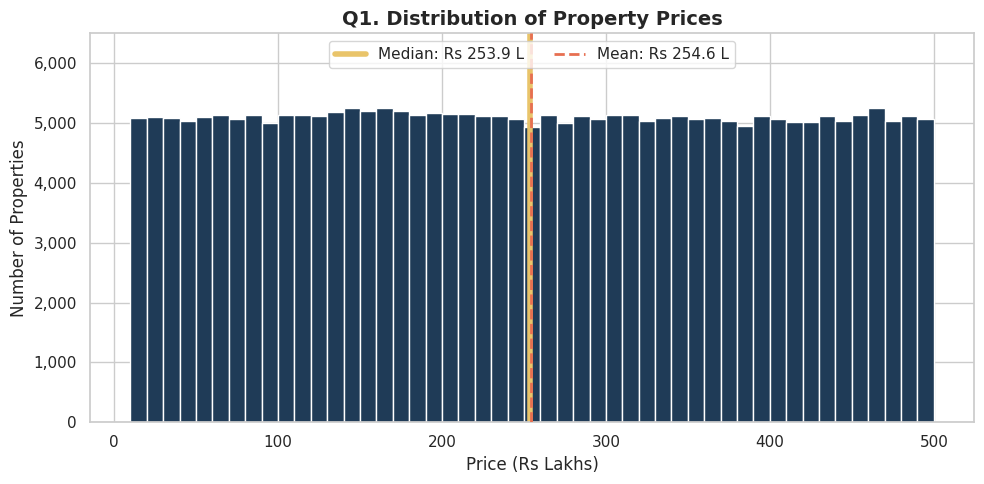

In [47]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(price, bins=range(10, 510, 10), color=PALETTE[0], edgecolor="white")

ax.axvline(price.median(), color=PALETTE[2], linewidth=4, label=f"Median: Rs {price.median():.1f} L")   # thick, drawn first
ax.axvline(price.mean(), color=PALETTE[3], linestyle="--", linewidth=2, zorder=3,
           label=f"Mean: Rs {price.mean():.1f} L")                                                   # dashed, on top

ax.set_ylim(0, 6500)
ax.legend(loc="upper center", ncol=2)
finish_chart(ax, "Q1. Distribution of Property Prices", "Price (Rs Lakhs)",
             "Number of Properties", "q1_price_distribution")

**Insight:** Property prices are spread almost perfectly evenly from ₹10 lakhs to ₹500 lakhs: every ₹10-lakh price range contains about 5,000 properties. The mean (₹254.59 lakhs) and median (₹253.87 lakhs) are nearly identical and skewness is 0.008 (practically zero), so there is no concentration of cheap or luxury homes.

**So what:** Investors at every budget level have the same amount of choice; a ₹50-lakh buyer has as many options as a ₹450-lakh buyer. In real Indian markets, prices are right-skewed (most homes affordable, few luxury), so this flat pattern confirms the data is synthetic and total price alone will not separate good from bad deals.

**Action:** Compare properties on price per sq ft relative to the city median rather than total price, and use price bands (Budget, Mid-range, Premium) as filters in the app so investors can focus on their budget range.

### Q2. What is the distribution of property sizes?
**Chart:** Histogram with mean and median lines, the best way to see the shape of a single numeric column, and directly comparable with the price distribution in Q1.

In [48]:
size = df["Size_in_SqFt"]
print(f"Mean: {size.mean():,.0f} | Median: {size.median():,.0f} | Skewness: {size.skew():.3f}")

Mean: 2,750 | Median: 2,747 | Skewness: 0.001


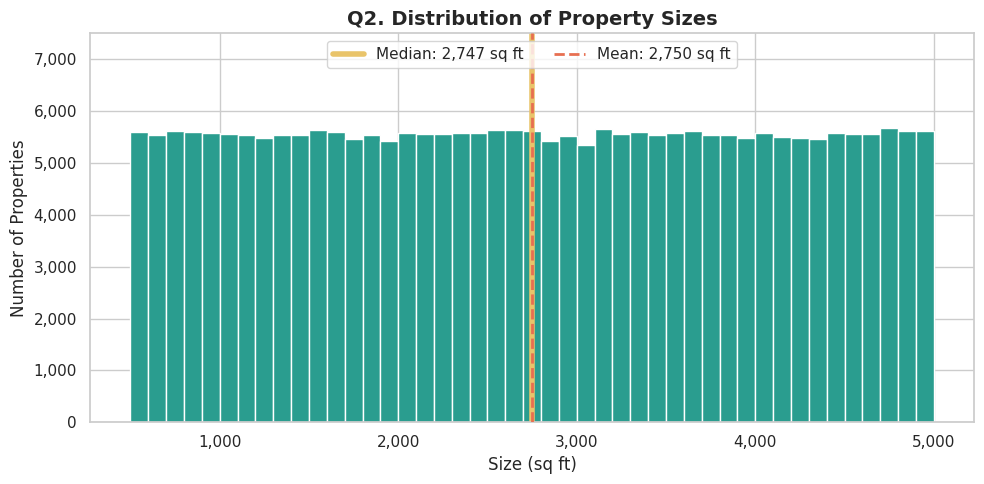

In [49]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(size, bins=range(500, 5100, 100), color=PALETTE[1], edgecolor="white")  # 45 buckets of 100 sq ft

ax.axvline(size.median(), color=PALETTE[2], linewidth=4, label=f"Median: {size.median():,.0f} sq ft")   # thicker, drawn first
ax.axvline(size.mean(), color=PALETTE[3], linestyle="--", linewidth=2, zorder=3,
           label=f"Mean: {size.mean():,.0f} sq ft")                                                  # zorder=3 = drawn on top

ax.set_ylim(0, 7500)
ax.legend(loc="upper center", ncol=2)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))  # 1000 -> 1,000 on x-axis too
finish_chart(ax, "Q2. Distribution of Property Sizes", "Size (sq ft)",
             "Number of Properties", "q2_size_distribution")

**Insight:** Property sizes are spread almost perfectly evenly from 500 to 5,000 sq ft: every 100-sq-ft range contains about 5,500 properties. The mean (2,750 sq ft) and median (2,747 sq ft) are almost identical, their lines overlap on the chart, and skewness is 0.001, so small, medium and large homes are equally common.

**So what:** Investors can find properties of any size equally easily, whether targeting small rentals for young professionals or large family homes. Real markets have far more small and mid-sized homes than very large ones, so this even spread is another sign of synthetic data.

**Action:** Use size bands (Small, Medium, Large) as an app filter matched to the target tenant, and judge value by price per sq ft rather than total price.

### Q3. How does price per sq ft vary by property type?
**Chart:** Box plot (outliers hidden; covered in Q5). A box plot compares the median and the middle 50% of values across groups, which is more informative than a bar of averages when data is skewed.

In [50]:
order = ["Apartment", "Independent House", "Villa"]
type_stats = df.groupby("Property_Type", observed=True)["Price_per_SqFt_Rs"].describe()[["25%", "50%", "75%", "mean"]].round(0)
print(type_stats.loc[order])
print(f"\nGap between highest and lowest median: {100 * (type_stats['50%'].max() / type_stats['50%'].min() - 1):.1f}%")

                       25%      50%       75%      mean
Property_Type                                          
Apartment         4,801.00 9,244.00 16,007.00 13,047.00
Independent House 4,868.00 9,305.00 16,029.00 13,102.00
Villa             4,738.00 9,190.00 15,924.00 13,026.00

Gap between highest and lowest median: 1.3%


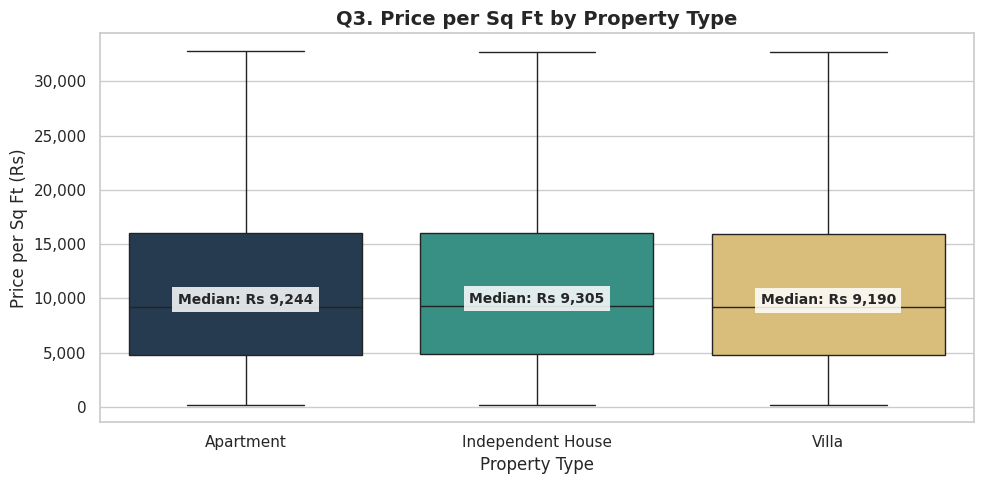

In [51]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df, x="Property_Type", y="Price_per_SqFt_Rs", order=order,
            hue="Property_Type", palette=PALETTE[:3], legend=False, showfliers=False, ax=ax)

for i, t in enumerate(order):  # write the median on each box
    m = type_stats.loc[t, "50%"]
    ax.text(i, m, f"Median: Rs {m:,.0f}", ha="center", va="bottom", fontsize=10, fontweight="bold",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.85))

finish_chart(ax, "Q3. Price per Sq Ft by Property Type", "Property Type",
             "Price per Sq Ft (Rs)", "q3_ppsf_by_type")

**Insight:** Price per sq ft is almost identical across property types: the median is ₹9,305 for independent houses, ₹9,244 for apartments and ₹9,190 for villas, a gap of only 1.3% (₹115 per sq ft). The middle 50% of properties for every type falls between roughly ₹4,800 and ₹16,000 per sq ft, and the means (₹13,026–₹13,102) sit well above the medians, showing the same right skew in every group.

**So what:** Unlike real Indian markets, where villas and independent houses usually command a premium for land and privacy, property type does not affect price per sq ft in this data. An investor pays the same rate whether buying an apartment or a villa, so type should be chosen on lifestyle or tenant demand, not on price.

**Action:** Use one benchmark (the city median price per sq ft) for all property types in the Good_Investment rule, and keep property type as a filter in the app for preference rather than as a pricing factor.

### Q4. Is there a relationship between property size and price?
**Chart:** Scatter plot of a random sample of 5,000 properties with a trend line fitted on all 250,000. A scatter plot is the standard way to show the relationship between two numeric variables; sampling avoids overplotting (dots merging into a solid block).

In [52]:
r_price = df["Size_in_SqFt"].corr(df["Price_in_Lakhs"])
r_ppsf  = df["Size_in_SqFt"].corr(df["Price_per_SqFt_Rs"])
print(f"Size vs Price:          r = {r_price:.3f}")
print(f"Size vs Price per sq ft: r = {r_ppsf:.3f}")

Size vs Price:          r = -0.003
Size vs Price per sq ft: r = -0.615


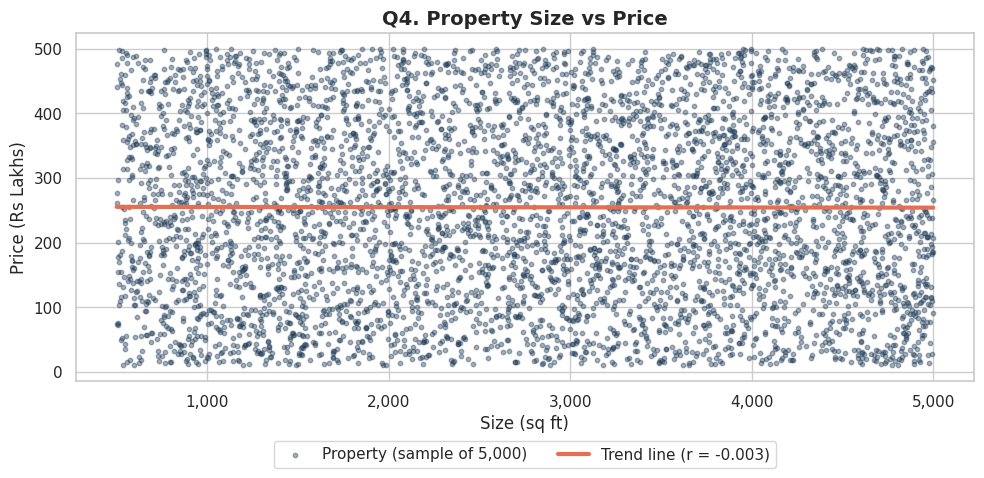

In [53]:
sample = df.sample(5000, random_state=42)  # random_state = same sample every run

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(sample["Size_in_SqFt"], sample["Price_in_Lakhs"], s=10, alpha=0.4, color=PALETTE[0], label="Property (sample of 5,000)")

slope, intercept = np.polyfit(df["Size_in_SqFt"], df["Price_in_Lakhs"], 1)  # straight trend line, all data
x = np.array([500, 5000])
ax.plot(x, slope * x + intercept, color=PALETTE[3], linewidth=3, label=f"Trend line (r = {r_price:.3f})")

ax.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.15))    # legend below the chart
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
finish_chart(ax, "Q4. Property Size vs Price", "Size (sq ft)", "Price (Rs Lakhs)", "q4_size_vs_price")

In [54]:
# Does the Good_Investment rule favour large homes?
(df.groupby("Size_Band", observed=True)["Good_Investment"].mean() * 100).round(1)

,Good_Investment
Size_Band,
Small,8.90
Medium,22.40
Large,40.10


**Insight:** There is no relationship between property size and total price (r = −0.003): the trend line is flat at about ₹254 lakhs, and a 500-sq-ft home is as likely to cost ₹450 lakhs as a 5,000-sq-ft home. Because price does not rise with size, larger homes have a much lower price per sq ft (r = −0.615). As a result, the Good_Investment rule rates 40.1% of large homes as good investments, compared with 22.4% of medium and only 8.9% of small homes.

**So what:** This breaks the most basic real-estate rule (bigger homes cost more), confirming the data is synthetic. For investors, large homes deliver far more space per rupee, but the rule's reliance on price per sq ft makes a large home 4.5 times more likely to qualify than a small one.

**Action:** Treat large homes priced below their city median as strong value opportunities, show size next to price per sq ft in the app so investors see why a property qualifies, and state this size bias clearly in the documentation as a known limitation of the rule.

### Q5. Are there outliers in price per sq ft or property size?
**Chart:** Two box plots side by side. Box plots mark outliers automatically as dots beyond 1.5 × IQR (the height of the box) from the box edges, the standard outlier rule.

In [55]:
def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr   # lower fence, upper fence

for col in ["Price_per_SqFt_Rs", "Size_in_SqFt"]:
    lo, hi = iqr_bounds(df[col])
    n = ((df[col] < lo) | (df[col] > hi)).sum()
    print(f"{col}: fences {lo:,.0f} to {hi:,.0f} | outliers: {n:,} ({n / len(df) * 100:.1f}%)")

lo, hi = iqr_bounds(df["Price_per_SqFt_Rs"])
out = df["Price_per_SqFt_Rs"] > hi
print(f"\nPrice-per-sq-ft outliers: median size {df.loc[out, 'Size_in_SqFt'].median():,.0f} sq ft, "
      f"median price Rs {df.loc[out, 'Price_in_Lakhs'].median():.0f} L")

Price_per_SqFt_Rs: fences -11,973 to 32,763 | outliers: 19,724 (7.9%)
Size_in_SqFt: fences -1,754 to 7,250 | outliers: 0 (0.0%)

Price-per-sq-ft outliers: median size 799 sq ft, median price Rs 401 L


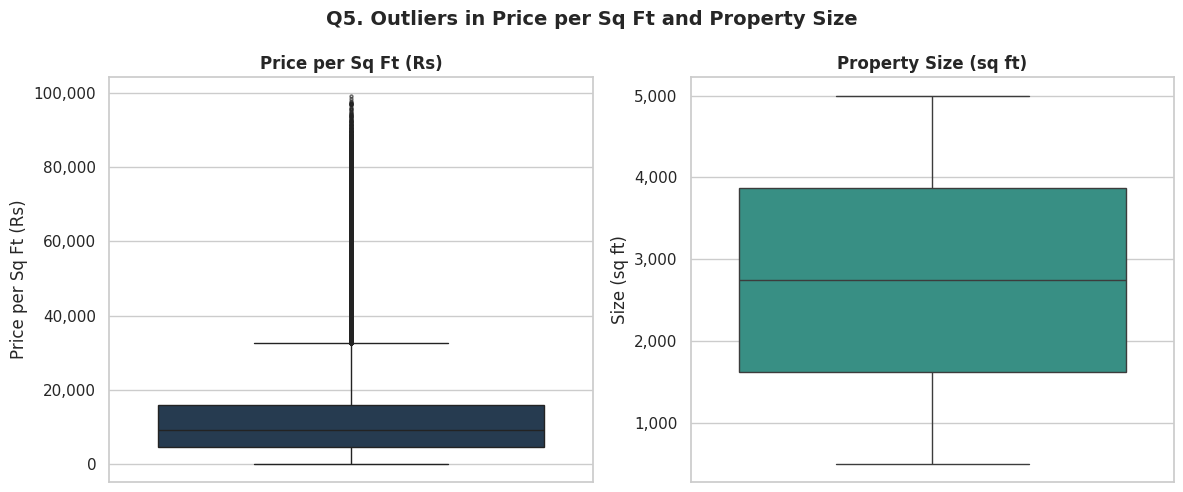

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df["Price_per_SqFt_Rs"], ax=axes[0], color=PALETTE[0], flierprops=dict(marker="o", markersize=2, alpha=0.3))
axes[0].set_title("Price per Sq Ft (Rs)", fontweight="bold")
axes[0].set_ylabel("Price per Sq Ft (Rs)")

sns.boxplot(y=df["Size_in_SqFt"], ax=axes[1], color=PALETTE[1])
axes[1].set_title("Property Size (sq ft)", fontweight="bold")
axes[1].set_ylabel("Size (sq ft)")

for a in axes:
    a.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))

fig.suptitle("Q5. Outliers in Price per Sq Ft and Property Size", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("charts/q5_outliers.png", dpi=150)
plt.show()

**Insight:** Property size has no outliers: all values fall between 500 and 5,000 sq ft, well inside the IQR fences (−1,754 to 7,250). Price per sq ft has 19,724 outliers (7.9%) above ₹32,763 per sq ft, reaching about ₹99,000. These outliers are small homes with high prices: their median size is only 799 sq ft and their median price ₹401 lakhs, more than 5 times the overall median rate of ₹9,245 per sq ft.

**So what:** The outliers are not data errors; price and size are each within normal ranges, and only their combination is extreme. They represent the riskiest, most overpriced properties for investors. All of them sit far above their city median, so the Good_Investment rule already excludes them automatically.

**Action:** Keep the outliers in the data (removing 7.9% would hide a real risk), use the median rather than the mean for price-per-sq-ft benchmarks, and flag properties above ₹32,763 per sq ft as "overpriced" in the app.

### Q6. What is the average price per sq ft by state?
**Chart:** Horizontal bar chart, sorted. Horizontal bars suit many categories with long names and keep labels readable. The axis starts at zero so small differences are not exaggerated; exact values are printed on each bar.

In [57]:
state_ppsf = df.groupby("State", observed=True)["Price_per_SqFt_Rs"].agg(["mean", "median"]).sort_values("mean")

print(f"Lowest:  {state_ppsf.index[0]} (mean Rs {state_ppsf['mean'].iloc[0]:,.0f})")
print(f"Highest: {state_ppsf.index[-1]} (mean Rs {state_ppsf['mean'].iloc[-1]:,.0f})")
print(f"Gap (mean): {100 * (state_ppsf['mean'].max() / state_ppsf['mean'].min() - 1):.1f}%")
print(f"Gap (median): {100 * (state_ppsf['median'].max() / state_ppsf['median'].min() - 1):.1f}%")

Lowest:  Punjab (mean Rs 12,931)
Highest: Karnataka (mean Rs 13,252)
Gap (mean): 2.5%
Gap (median): 3.3%


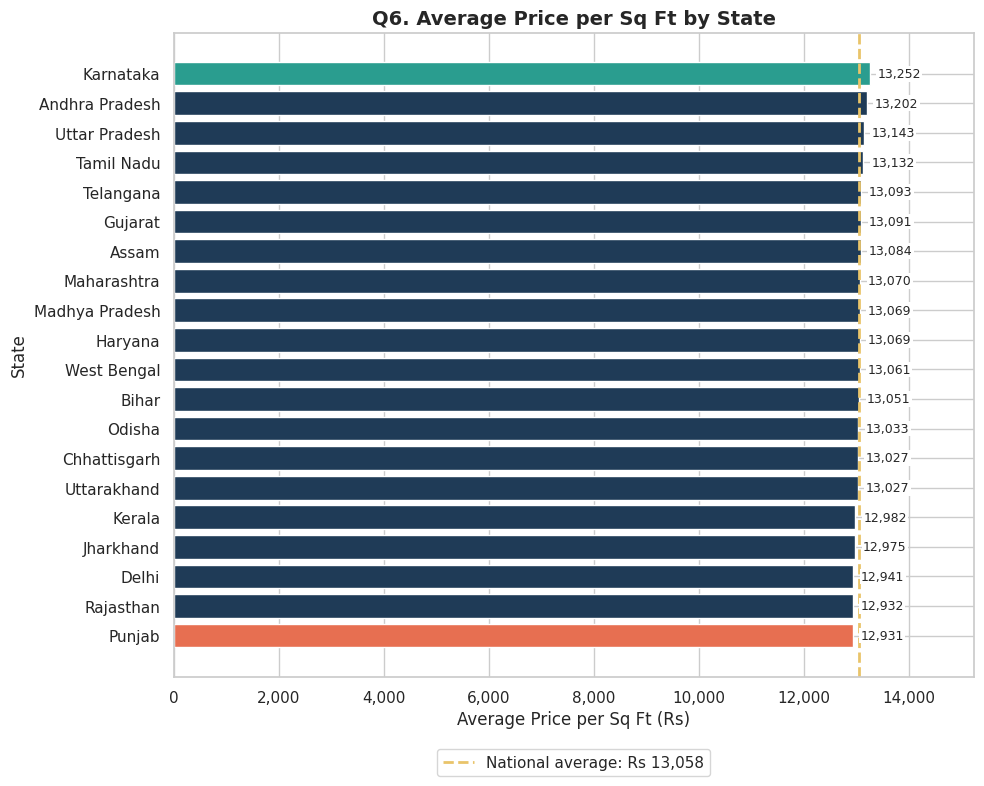

In [58]:
avg = state_ppsf["mean"]
colors = [PALETTE[3] if s == avg.idxmin() else PALETTE[1] if s == avg.idxmax() else PALETTE[0] for s in avg.index]

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(avg.index, avg.values, color=colors)

for i, v in enumerate(avg.values):
    ax.text(v + 150, i, f"{v:,.0f}", va="center", fontsize=9, zorder=4,
            bbox=dict(facecolor="white", edgecolor="none", pad=1))

ax.axvline(df["Price_per_SqFt_Rs"].mean(), color=PALETTE[2], linestyle="--", linewidth=2,
           label=f"National average: Rs {df['Price_per_SqFt_Rs'].mean():,.0f}")
ax.set_xlim(0, avg.max() * 1.15)                         # room for labels
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1))
finish_chart(ax, "Q6. Average Price per Sq Ft by State", "Average Price per Sq Ft (Rs)",
             "State", "q6_ppsf_by_state", comma_axis="x")

**Insight:** Average price per sq ft is almost the same in every state, from ₹12,931 in Punjab to ₹13,252 in Karnataka, a gap of only 2.5% (₹321 per sq ft); the gap between state medians is similarly small at 3.3%. Every state sits within about ±1.5% of the national average of ₹13,058, and Delhi (₹12,941) and Maharashtra (₹13,070) are close to the bottom and middle of the ranking.

**So what:** In real Indian markets, Delhi, Maharashtra and Karnataka are among the most expensive states, often several times costlier per sq ft than smaller states, so this flat pattern confirms the data is synthetic. For an investor in this dataset, the state chosen makes almost no difference to the price paid per sq ft; on a 1,000-sq-ft home, the cheapest and costliest states differ by only about ₹3.2 lakhs.

**Action:** Do not use state as a value signal; compare each property with its city median price per sq ft instead, and keep State as an app filter for investors' location preferences.

### Q7. What is the average property price by city?
**Chart:** Sorted horizontal bar chart (taller to fit 42 cities), consistent with Q6. The axis starts at zero and exact averages are printed on each bar.

In [59]:
city_price = df.groupby("City", observed=True)["Price_in_Lakhs"].agg(["mean", "median", "count"]).sort_values("mean")

print(f"Lowest:  {city_price.index[0]} (Rs {city_price['mean'].iloc[0]:.1f} L)")
print(f"Highest: {city_price.index[-1]} (Rs {city_price['mean'].iloc[-1]:.1f} L)")
print(f"Gap (mean): {100 * (city_price['mean'].max() / city_price['mean'].min() - 1):.1f}%")
print(f"Properties per city: {city_price['count'].min():,} to {city_price['count'].max():,}")

Lowest:  Cuttack (Rs 250.8 L)
Highest: Bangalore (Rs 258.5 L)
Gap (mean): 3.1%
Properties per city: 4,063 to 6,461


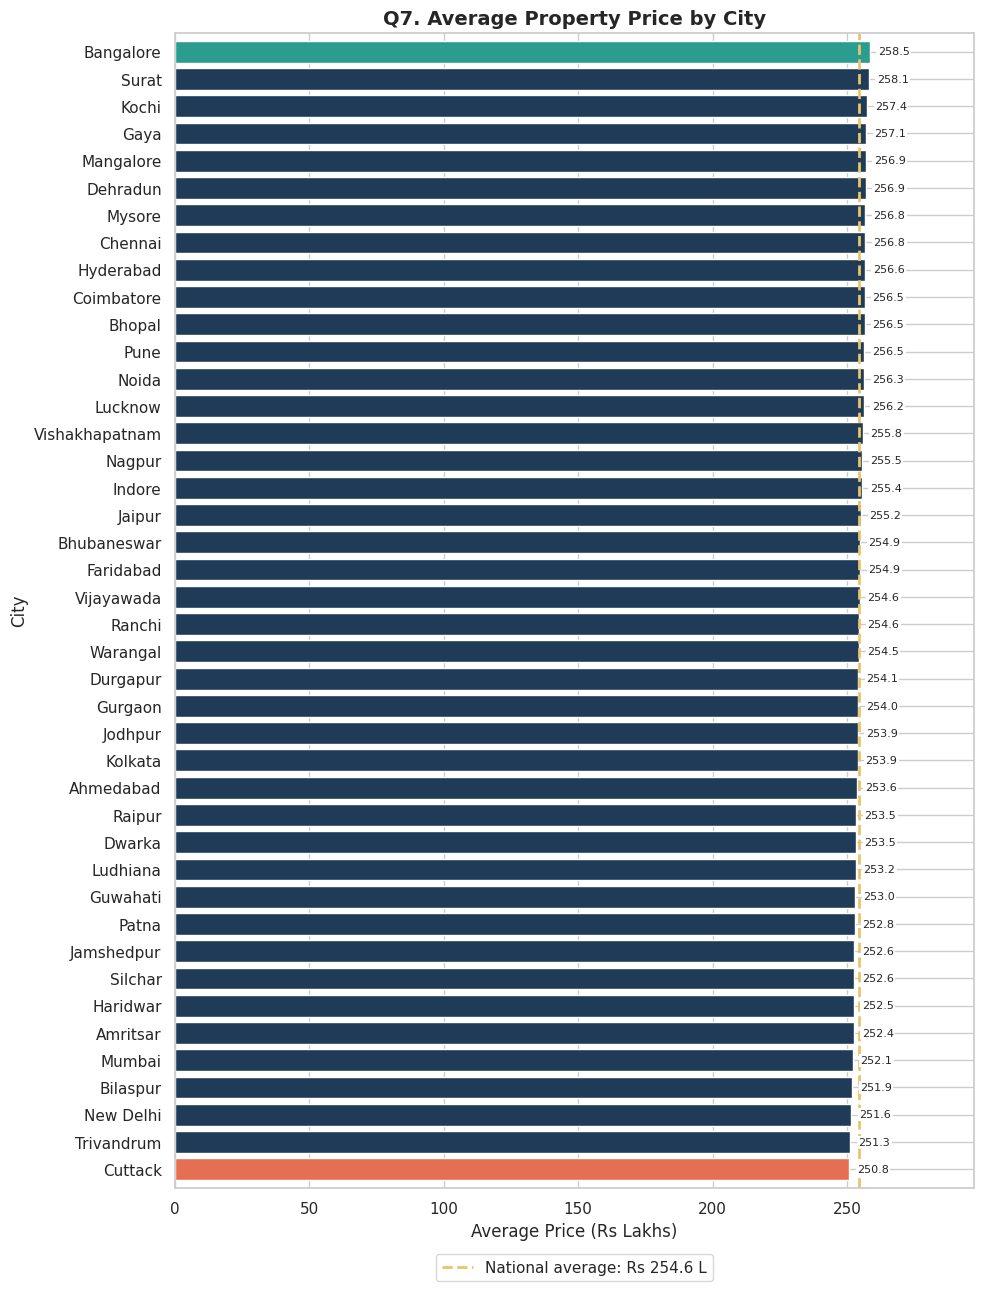

In [60]:
avg = city_price["mean"]
colors = [PALETTE[3] if c == avg.idxmin() else PALETTE[1] if c == avg.idxmax() else PALETTE[0] for c in avg.index]

fig, ax = plt.subplots(figsize=(10, 13))                  # taller for 42 cities
ax.barh(avg.index, avg.values, color=colors)

for i, v in enumerate(avg.values):
    ax.text(v + 3, i, f"{v:.1f}", va="center", fontsize=8, zorder=4,
            bbox=dict(facecolor="white", edgecolor="none", pad=1))

ax.axvline(df["Price_in_Lakhs"].mean(), color=PALETTE[2], linestyle="--", linewidth=2,
           label=f"National average: Rs {df['Price_in_Lakhs'].mean():.1f} L")
ax.set_xlim(0, avg.max() * 1.15)
ax.set_ylim(-0.7, len(avg) - 0.3)                        # trims empty space above and below the bars
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.05))
finish_chart(ax, "Q7. Average Property Price by City", "Average Price (Rs Lakhs)",
             "City", "q7_price_by_city", comma_axis="x")

**Insight:** Average property price is almost the same in all 42 cities, from ₹250.8 lakhs in Cuttack to ₹258.5 lakhs in Bangalore, a gap of only 3.1% (₹7.7 lakhs). Every city has between 4,063 and 6,461 properties, so these averages are reliable. Notably, Mumbai (₹252.1 lakhs) and New Delhi (₹251.6 lakhs) are among the five cheapest cities.

**So what:** In the real Indian market, Mumbai and Delhi are the most expensive cities, often several times costlier than tier-2 cities like Cuttack, so this result confirms that location does not drive price in this synthetic dataset. For an investor here, the same budget buys a similar property in any city, so city choice should depend on personal or rental-demand factors rather than price.

**Action:** Use city as a filter in the app for location preference, benchmark each property against its own city median, and clearly note in the documentation that city-level price differences in this data do not reflect real market conditions.

### Q8. What is the median age of properties by locality?
**Chart:** Bar chart showing how many of the 500 localities have each median age. With 500 localities, ranking individual ones would highlight random differences; showing the spread of all 500 medians answers whether localities genuinely differ. Note: locality names are codes reused across all 42 cities (see Phase 1).

In [61]:
loc_age = df.groupby("Locality", observed=True)["Age_of_Property"].median()

print(f"Localities: {len(loc_age)} | median age range: {loc_age.min()} to {loc_age.max()} years")
print(f"Overall median age: {df['Age_of_Property'].median()} years")
print(f"Localities with median age between 17 and 20: {loc_age.between(17, 20).mean() * 100:.0f}%")
print("Newest 3:", loc_age.nsmallest(3).to_dict())
print("Oldest 3:", loc_age.nlargest(3).to_dict())

Localities: 500 | median age range: 16.0 to 21.0 years
Overall median age: 18.0 years
Localities with median age between 17 and 20: 99%
Newest 3: {'Locality_443': 16.0, 'Locality_10': 17.0, 'Locality_118': 17.0}
Oldest 3: {'Locality_403': 21.0, 'Locality_72': 21.0, 'Locality_1': 20.0}


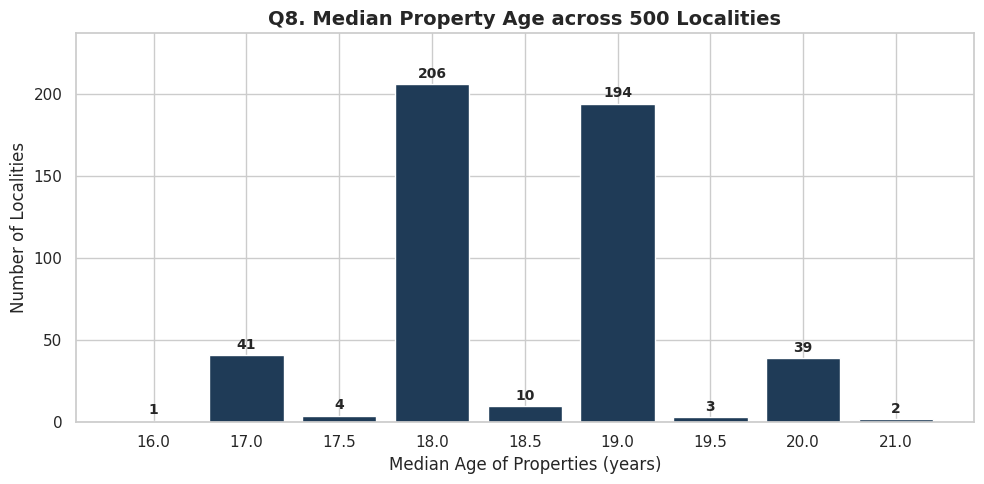

In [62]:
counts = loc_age.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(counts.index.astype(str), counts.values, color=PALETTE[0])

for i, v in enumerate(counts.values):                     # count on top of each bar, horizontal
    ax.text(i, v + 2, str(v), ha="center", va="bottom", fontsize=10, fontweight="bold")

ax.set_ylim(0, counts.max() * 1.15)
finish_chart(ax, "Q8. Median Property Age across 500 Localities", "Median Age of Properties (years)",
             "Number of Localities", "q8_median_age_by_locality")

**Insight:** The median property age is almost identical across all 500 localities: 99% have a median between 17 and 20 years, and 400 localities (80%) sit at exactly 18 or 19 years, either side of the overall median of 18. The full range is only 16 years (Locality_443) to 21 years (Locality_403 and Locality_72). Because ages are spread evenly from 2 to 35 years, chance alone decides whether a locality's median lands on 18 or 19.

**So what:** No locality is genuinely newer or older than the others; the small differences come from random variation, not real development patterns. Since locality names are codes reused across all 42 cities, these results cannot identify a real new or old neighbourhood. For investors, property age must be judged property by property, not by locality.

**Action:** Evaluate age at the individual property level using the Age_Group bands (New, Moderate, Old), and avoid ranking localities by age in the app, as the differences would be misleading.

### Q9. How is BHK distributed across cities?
**Chart:** Heatmap of the percentage of each city's properties by BHK (1–5), with values printed in each cell. A diverging colour scale is centred on 20% (an equal share across 5 BHK types): white = 20%, teal = above, coral = below. The scale (17–23%) is just wider than the actual values, so colours show the direction of differences without exaggerating their size.

In [63]:
bhk_city = (pd.crosstab(df["City"], df["BHK"], normalize="index") * 100).round(1)  # % per row (city)

print("Overall BHK share (%):")
print((df["BHK"].value_counts(normalize=True).sort_index() * 100).round(1).to_dict())

cells = bhk_city.stack()
print(f"\nLowest cell:  {cells.min()}% ({cells.idxmin()[0]}, {cells.idxmin()[1]} BHK)")
print(f"Highest cell: {cells.max()}% ({cells.idxmax()[0]}, {cells.idxmax()[1]} BHK)")

Overall BHK share (%):
{1: 20.1, 2: 19.9, 3: 20.0, 4: 19.9, 5: 20.1}

Lowest cell:  18.6% (Gaya, 3 BHK)
Highest cell: 22.0% (Gaya, 1 BHK)


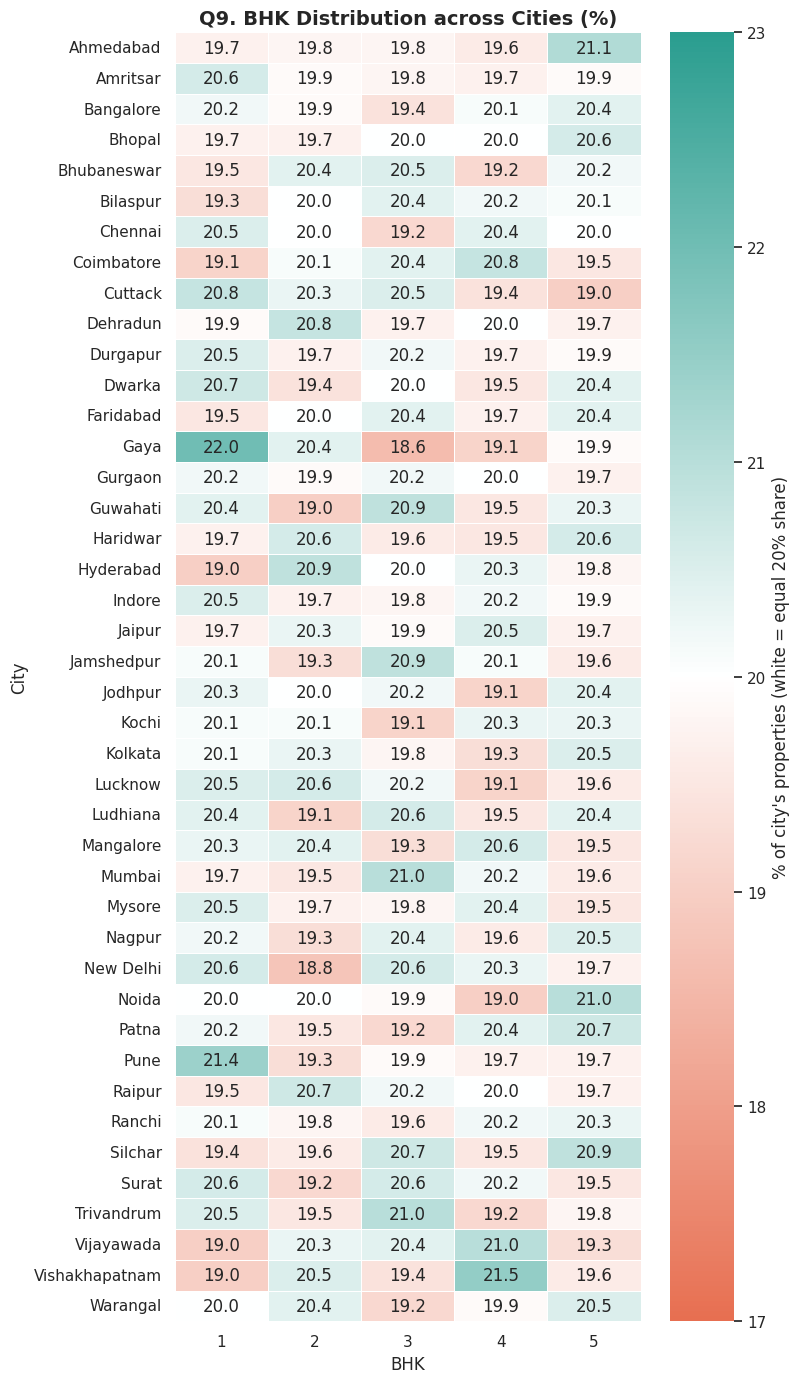

In [64]:
cmap = sns.blend_palette([PALETTE[3], "white", PALETTE[1]], as_cmap=True)  # coral -> white -> teal

fig, ax = plt.subplots(figsize=(8, 14))
sns.heatmap(bhk_city, annot=True, fmt=".1f", cmap=cmap, center=20, vmin=17, vmax=23,
            linewidths=0.5, cbar_kws={"label": "% of city's properties (white = equal 20% share)"}, ax=ax)
ax.tick_params(axis="y", rotation=0)
finish_chart(ax, "Q9. BHK Distribution across Cities (%)", "BHK", "City",
             "q9_bhk_by_city", comma_axis=None)

**Insight:** BHK types are spread evenly in every city: overall, 1, 2, 3, 4 and 5 BHK homes each make up about 20% of properties (19.9%–20.1%), and all 210 city-by-BHK shares fall between 18.6% and 22.0%. Teal (above 20%) and coral (below 20%) cells are scattered randomly with no city or BHK type consistently above or below the equal share; the largest deviations both occur in Gaya (22.0% 1 BHK, 18.6% 3 BHK), reflecting random variation rather than a real local pattern.

**So what:** Every city offers the same choice of home sizes, so an investor targeting a particular BHK type (for example, 1–2 BHK rentals for young professionals or 3–4 BHK family homes) will find similar supply anywhere. Real Indian cities differ sharply (metros have more compact 1–2 BHK flats, smaller cities more large homes), which again confirms the data is synthetic.

**Action:** Keep BHK as a key app filter so investors can match properties to their target tenants, and choose the city on other criteria, since BHK availability does not differ between cities.

### Q10. What are the price trends for the top 5 most expensive localities?
**Chart:** Line chart of average price by 5-year construction period for the 5 localities with the highest average price, with the all-property average as a benchmark. The dataset has no sale date, so the "trend" is across construction years (Year_Built), not over market time. Years are grouped into 5-year periods so each point averages about 70 properties instead of ~15.

In [65]:
loc_price = df.groupby("Locality", observed=True)["Price_in_Lakhs"].agg(["mean", "median", "count"])
top5 = loc_price.sort_values("mean", ascending=False).head(5)

print(top5.round(1))
print(f"\nAll-property average: Rs {df['Price_in_Lakhs'].mean():.1f} L")
print(f"Top-5 average is {100 * (top5['mean'].mean() / df['Price_in_Lakhs'].mean() - 1):.1f}% above the overall average")

               mean  median  count
Locality                          
Locality_395 275.40  282.70    461
Locality_366 273.40  282.30    526
Locality_497 270.00  273.70    491
Locality_360 269.80  278.80    505
Locality_203 269.00  280.30    522

All-property average: Rs 254.6 L
Top-5 average is 6.7% above the overall average


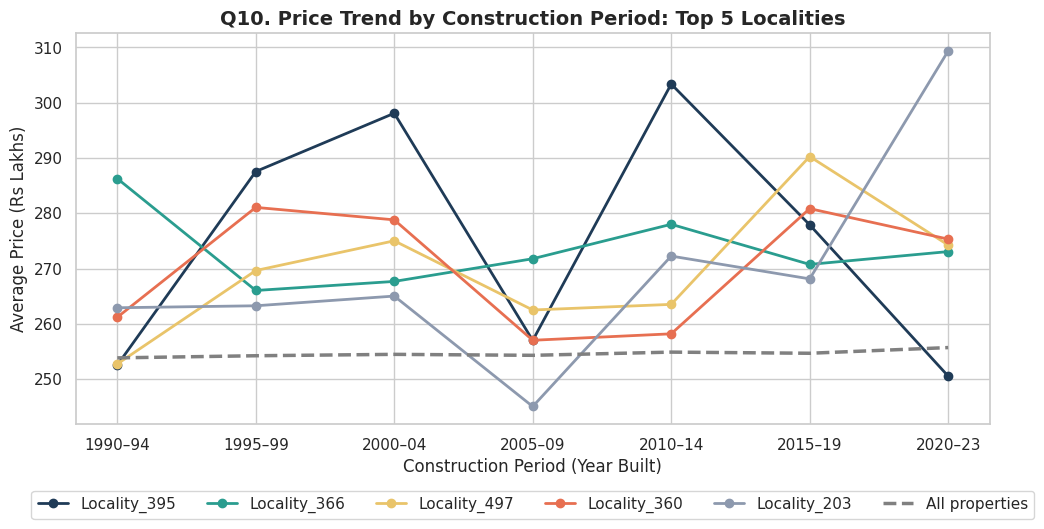

In [66]:
period = pd.cut(df["Year_Built"], bins=[1989, 1994, 1999, 2004, 2009, 2014, 2019, 2023],
                labels=["1990–94", "1995–99", "2000–04", "2005–09", "2010–14", "2015–19", "2020–23"])
d = df.assign(Period=period)

trend = d[d["Locality"].isin(top5.index)].groupby(["Period", "Locality"], observed=True)["Price_in_Lakhs"].mean().unstack()
overall = d.groupby("Period", observed=True)["Price_in_Lakhs"].mean()

fig, ax = plt.subplots(figsize=(11, 5.5))
for i, loc in enumerate(top5.index):
    ax.plot(trend.index.astype(str), trend[loc], marker="o", linewidth=2, color=PALETTE[i], label=loc)
ax.plot(overall.index.astype(str), overall.values, color="grey", linestyle="--", linewidth=2.5, label="All properties")

ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=6)
finish_chart(ax, "Q10. Price Trend by Construction Period: Top 5 Localities", "Construction Period (Year Built)",
             "Average Price (Rs Lakhs)", "q10_top5_locality_trend")

**Insight:** The five most expensive localities (Locality_395, 366, 497, 360 and 203) average ₹269–275 lakhs, only 6.7% above the overall average of ₹254.6 lakhs. Their prices swing sharply and randomly across construction periods: Locality_395, the top-ranked, ranges from ₹303 lakhs (2010–14 builds) to ₹250 lakhs (2020–23 builds), and Locality_203 falls to ₹245 lakhs for 2005–09 builds, both below the overall average. Across all properties, average price stays flat at ₹254–256 lakhs in every construction period.

**So what:** These localities are not genuine premium areas; their slightly higher averages come from random variation, and no locality is consistently expensive across periods. Newer construction also does not command a higher price in this data, unlike real markets where new builds usually carry a premium. Since the dataset has no sale dates and locality names are codes shared by all 42 cities, these lines show differences by build year, not market price growth.

**Action:** Do not use locality rankings or build year to predict future value; rely on the property-level Good_Investment rule and the stated 5% growth assumption for future price estimates, and note in the documentation that true price trends would require sale-date data.

### Q11. How are numeric features correlated with each other?
**Chart:** Correlation heatmap (lower triangle) of 14 numeric features. A heatmap shows all 91 pair-wise correlations at once. The colour scale covers the full range −1 to +1 (coral = negative, white = none, teal = positive) so only genuinely strong relationships stand out. Columns calculated from each other (e.g., Year_Built vs Age, Future_Price vs Price) are excluded to avoid artificial correlations.

In [67]:
num_cols = {"Price_in_Lakhs": "Price", "Price_per_SqFt_Rs": "Price/SqFt", "Size_in_SqFt": "Size",
            "BHK": "BHK", "Age_of_Property": "Age", "Floor_No": "Floor", "Total_Floors": "Total Floors",
            "Nearby_Schools": "Schools", "Nearby_Hospitals": "Hospitals", "Transport_Level": "Transport",
            "Amenities_Count": "Amenities", "Has_Parking": "Parking", "Has_Security": "Security",
            "Is_Ready_To_Move": "Ready to Move"}

corr = df[list(num_cols)].rename(columns=num_cols).corr()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))   # each pair once
pairs = upper.stack().sort_values(key=abs, ascending=False)
print("Strongest 5 pairs:\n", pairs.head(5).round(3))
print(f"\nPairs with |r| < 0.05 (no link): {(pairs.abs() < 0.05).sum()} of {len(pairs)}")

Strongest 5 pairs:
 Price/SqFt  Size           -0.61
Price       Price/SqFt      0.56
Floor       Total Floors    0.50
Size        Age            -0.00
            Floor          -0.00
dtype: float64

Pairs with |r| < 0.05 (no link): 88 of 91


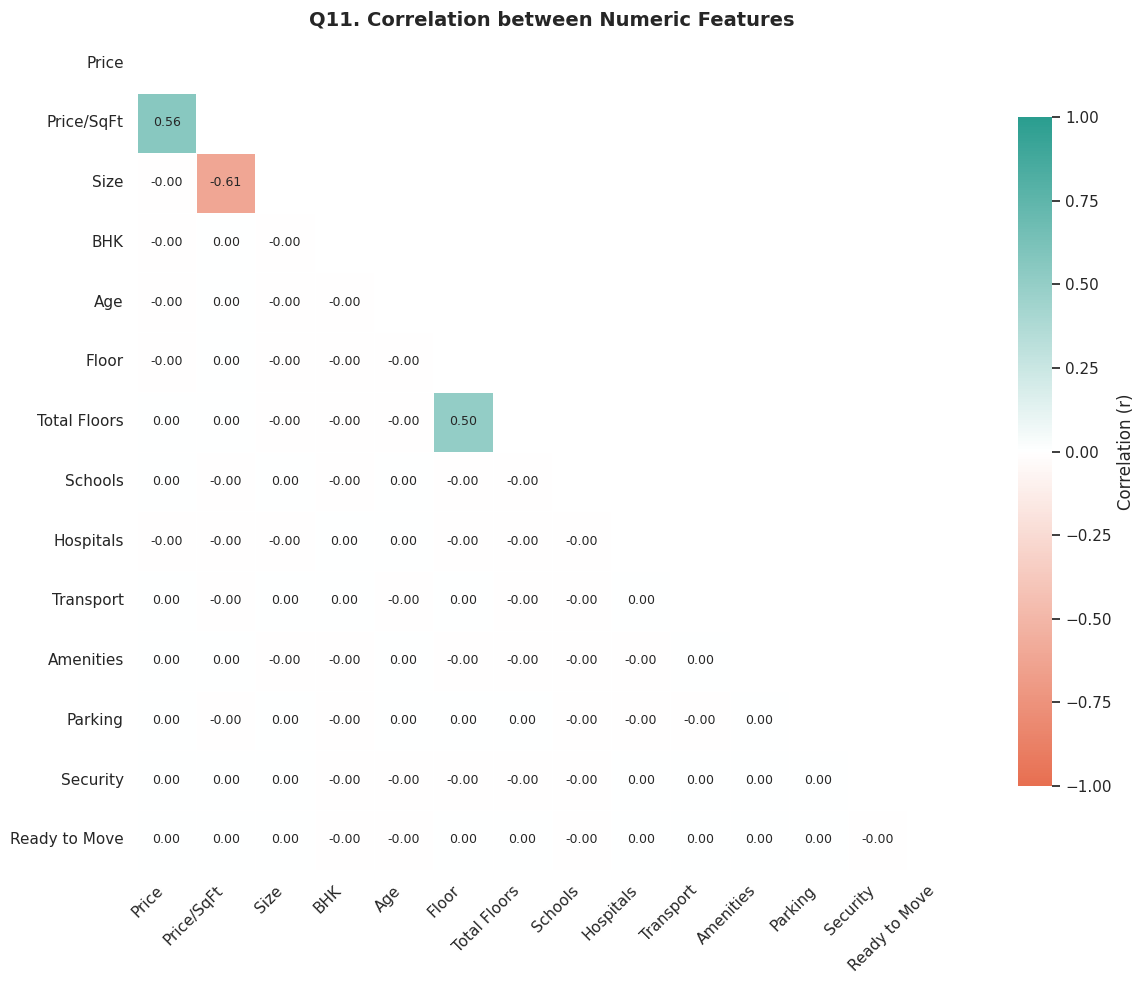

In [68]:
mask = np.triu(np.ones_like(corr, dtype=bool))                       # hide upper half + diagonal
cmap = sns.blend_palette([PALETTE[3], "white", PALETTE[1]], as_cmap=True)

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap=cmap, center=0, vmin=-1, vmax=1,
            linewidths=0.5, annot_kws={"size": 9}, cbar_kws={"label": "Correlation (r)", "shrink": 0.8}, ax=ax)
ax.tick_params(axis="x", rotation=45)
plt.setp(ax.get_xticklabels(), ha="right")                            # align slanted labels to their columns
ax.tick_params(axis="y", rotation=0)
ax.grid(False)   # remove background grid lines from the empty triangle
finish_chart(ax, "Q11. Correlation between Numeric Features", "", "", "q11_correlation_heatmap", comma_axis=None)

**Insight:** 88 of the 91 feature pairs have no relationship (|r| < 0.05). Only three pairs are correlated, and all three are mechanical rather than market-driven: size and price per sq ft (r = −0.61) and price and price per sq ft (r = +0.56), because price per sq ft is calculated from price and size; and floor number and total floors (r = +0.50), which was created by our cleaning step (swapping impossible values makes the floor always the smaller number). Price has zero correlation with size, BHK, age, schools, hospitals, transport, amenities, parking, security and readiness.

**So what:** No property feature drives price in this dataset, which is the clearest evidence that it is synthetic; in real markets, size, location and amenities strongly influence price. For investors, this means price per sq ft relative to the city median is the only reliable value signal, and features such as amenities and infrastructure should be judged as quality factors, not as reasons for a higher price.

**Action:** Build the Good_Investment rule on price per sq ft versus the city median plus independent quality criteria (as done), avoid any claim that features "increase price", and record in the documentation that the floor correlation is a by-product of data cleaning.

### Q12. How do nearby schools relate to price per sq ft?
**Chart:** Box plot of price per sq ft for each number of nearby schools (1–10), outliers hidden, with a line joining the medians. Box plots compare the typical value and spread across groups; the median line makes any upward or downward trend easy to see.

In [69]:
sch = df.groupby("Nearby_Schools")["Price_per_SqFt_Rs"].agg(["median", "count"])
r_sch = df["Nearby_Schools"].corr(df["Price_per_SqFt_Rs"])

print(sch.round(0).T)
print(f"\nCorrelation (r): {r_sch:.3f}")
print(f"Gap between highest and lowest median: {100 * (sch['median'].max() / sch['median'].min() - 1):.1f}%")

Nearby_Schools        1         2         3         4         5         6   \
median          9,261.00  9,291.00  9,273.00  9,259.00  9,188.00  9,352.00   
count          25,360.00 24,851.00 25,045.00 24,739.00 25,023.00 24,824.00   

Nearby_Schools        7         8         9         10  
median          9,232.00  9,144.00  9,265.00  9,212.00  
count          24,808.00 25,290.00 24,823.00 25,237.00  

Correlation (r): -0.000
Gap between highest and lowest median: 2.3%


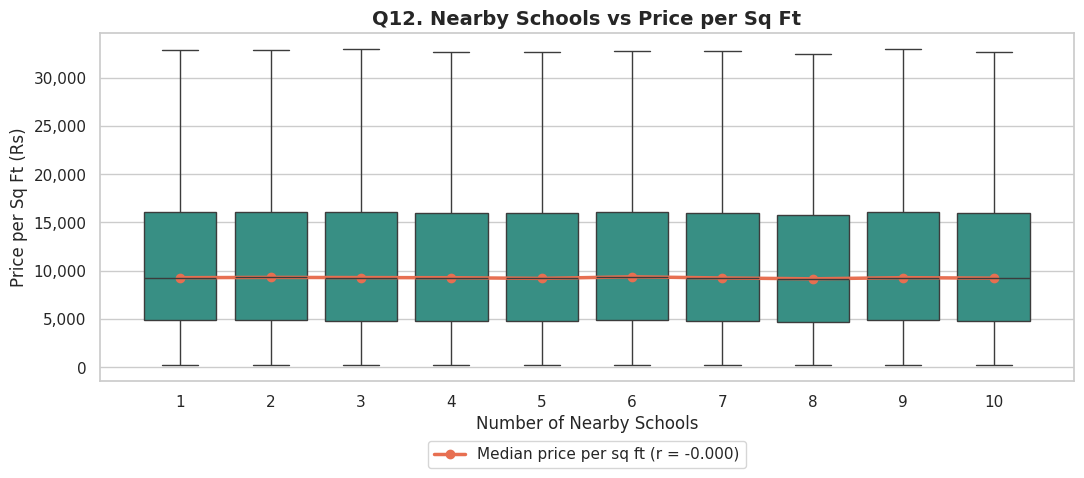

In [70]:
fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=df, x="Nearby_Schools", y="Price_per_SqFt_Rs", color=PALETTE[1], showfliers=False, ax=ax)
ax.plot(range(10), sch["median"].values, color=PALETTE[3], marker="o", linewidth=2.5,
        label=f"Median price per sq ft (r = {r_sch:.3f})")

ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15))
finish_chart(ax, "Q12. Nearby Schools vs Price per Sq Ft", "Number of Nearby Schools",
             "Price per Sq Ft (Rs)", "q12_schools_vs_ppsf")

**Insight:** The number of nearby schools has no effect on price per sq ft (r = −0.000). Median prices stay within a narrow band from ₹9,144 (8 schools) to ₹9,352 (6 schools), a gap of only 2.3%, and properties with 10 nearby schools (₹9,212) are no more expensive than those with just 1 (₹9,261). Each school count has about 25,000 properties, and all ten box plots have almost identical medians and spreads.

**So what:** In real Indian cities, homes near good schools usually command a clear premium because families compete for them; here, school access comes "free" at the same price. For investors, a property with many nearby schools offers extra appeal to family tenants and future buyers without costing more, which makes it better value.

**Action:** Treat nearby schools as a quality factor (it is already part of the Infrastructure Score in the Good_Investment rule) rather than a price driver, and highlight high-school-access properties in the app for investors targeting family rentals.

### Q13. How do nearby hospitals relate to price per sq ft?
**Chart:** Box plot of price per sq ft for each number of nearby hospitals (1–10), outliers hidden, with a line joining the medians. The layout matches Q12 so schools and hospitals can be compared directly.

In [71]:
hos = df.groupby("Nearby_Hospitals")["Price_per_SqFt_Rs"].agg(["median", "count"])
r_hos = df["Nearby_Hospitals"].corr(df["Price_per_SqFt_Rs"])

print(hos.round(0).T)
print(f"\nCorrelation (r): {r_hos:.3f}")
print(f"Gap between highest and lowest median: {100 * (hos['median'].max() / hos['median'].min() - 1):.1f}%")

Nearby_Hospitals        1         2         3         4         5         6   \
median            9,256.00  9,309.00  9,349.00  9,270.00  9,149.00  9,128.00   
count            25,075.00 24,960.00 24,834.00 25,168.00 25,102.00 25,082.00   

Nearby_Hospitals        7         8         9         10  
median            9,334.00  9,224.00  9,283.00  9,196.00  
count            24,887.00 24,891.00 25,014.00 24,987.00  

Correlation (r): -0.000
Gap between highest and lowest median: 2.4%


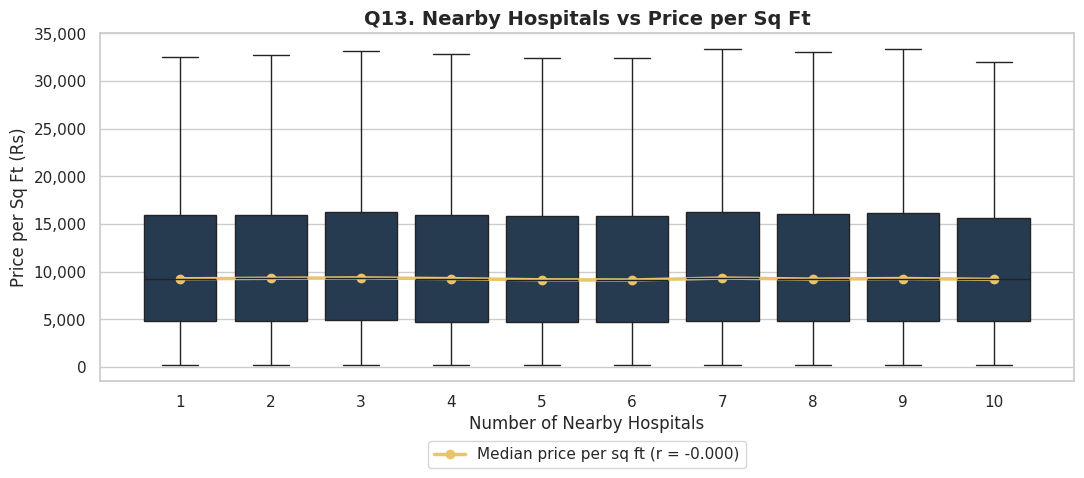

In [72]:
fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=df, x="Nearby_Hospitals", y="Price_per_SqFt_Rs", color=PALETTE[0], showfliers=False, ax=ax)
ax.plot(range(10), hos["median"].values, color=PALETTE[2], marker="o", linewidth=2.5,
        label=f"Median price per sq ft (r = {r_hos:.3f})")

ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15))
finish_chart(ax, "Q13. Nearby Hospitals vs Price per Sq Ft", "Number of Nearby Hospitals",
             "Price per Sq Ft (Rs)", "q13_hospitals_vs_ppsf")

**Insight:** The number of nearby hospitals has no effect on price per sq ft (r = −0.000). Median prices range only from ₹9,128 (6 hospitals) to ₹9,349 (3 hospitals), a 2.4% gap almost identical to the 2.3% seen for schools, and properties with 10 nearby hospitals (₹9,196) cost no more than those with 1 (₹9,256). Every hospital count has about 25,000 properties, and all ten box plots are nearly identical.

**So what:** In real markets, good healthcare access adds value, especially for families and elderly buyers; here it carries no price premium, so investors get better healthcare access at no extra cost. Together with Q12, this shows that none of the infrastructure factors (schools, hospitals) are priced into this market.

**Action:** Use nearby hospitals as a quality factor through the Infrastructure Score rather than a price driver, and highlight high-healthcare-access properties in the app for investors targeting retirement or family rentals.

### Q14. How does price vary by furnished status?
**Chart:** Bar chart of average price by furnished status, ordered from least to most furnished. With only three groups and no outliers in total price, a bar of averages is the clearest comparison; the axis starts at zero so small differences are not exaggerated.

In [73]:
furn = df.groupby("Furnished_Status", observed=True)["Price_in_Lakhs"].agg(["mean", "median", "count"])
print(furn.round(1))
print(f"\nGap between highest and lowest average: {100 * (furn['mean'].max() / furn['mean'].min() - 1):.1f}%")

                   mean  median  count
Furnished_Status                      
Unfurnished      255.00  254.20  83408
Semi-furnished   254.30  253.80  83374
Furnished        254.40  253.60  83218

Gap between highest and lowest average: 0.3%


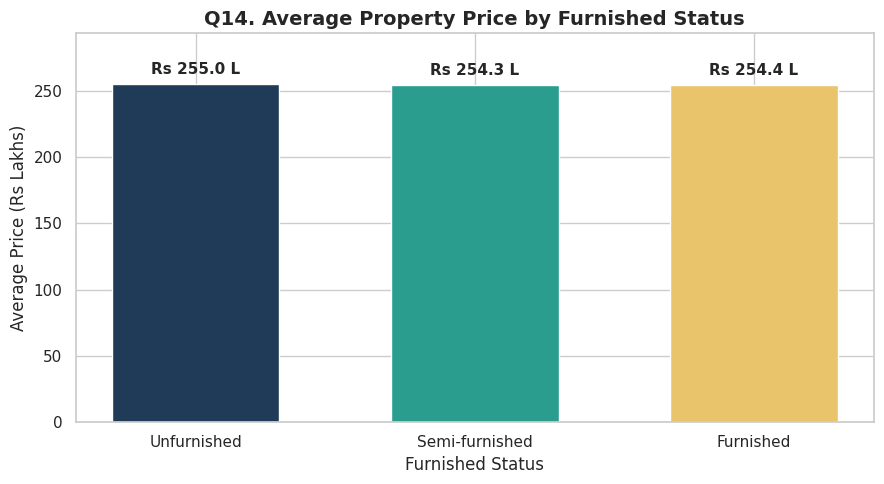

In [74]:
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(furn.index.astype(str), furn["mean"], color=PALETTE[:3], width=0.6)

for b, v in zip(bars, furn["mean"]):                       # value label above each bar, horizontal
    ax.text(b.get_x() + b.get_width() / 2, v + 5, f"Rs {v:.1f} L", ha="center", va="bottom",
            fontsize=11, fontweight="bold")

ax.set_ylim(0, furn["mean"].max() * 1.15)
finish_chart(ax, "Q14. Average Property Price by Furnished Status", "Furnished Status",
             "Average Price (Rs Lakhs)", "q14_price_by_furnishing")

**Insight:** Furnishing has no effect on property price: unfurnished homes average ₹255.0 lakhs, semi-furnished ₹254.3 lakhs and furnished ₹254.4 lakhs, a gap of only 0.3% (₹0.7 lakhs), with medians showing the same pattern. Each group contains about 83,000 properties, and unfurnished homes are actually marginally the most expensive.

**So what:** In real markets, furnished homes carry a premium for the furniture, appliances and fittings included; here, investors get furnishing at no extra cost. A furnished property is therefore better value, as it can be rented out immediately and at higher rent without paying more upfront.

**Action:** Prefer furnished or semi-furnished properties when prices are equal, highlight furnishing as a value-adding feature in the app, and do not pay a premium for furnishing in this market.

### Q15. How does price per sq ft vary by facing direction?
**Chart:** Bar chart of median price per sq ft for each facing direction. The median is used because price per sq ft is right-skewed with outliers (Q5); the axis starts at zero. In India, East- and North-facing homes are traditionally preferred under Vastu, so a premium would be expected in a real market.

In [77]:
order = ["North", "East", "South", "West"]
face = df.groupby("Facing", observed=True)["Price_per_SqFt_Rs"].agg(["median", "mean", "count"]).loc[order]
print(face.round(0))
print(f"\nGap between highest and lowest median: {100 * (face['median'].max() / face['median'].min() - 1):.1f}%")

         median      mean  count
Facing                          
North  9,219.00 13,025.00  62637
East   9,234.00 13,024.00  62269
South  9,225.00 13,044.00  62337
West   9,308.00 13,140.00  62757

Gap between highest and lowest median: 1.0%


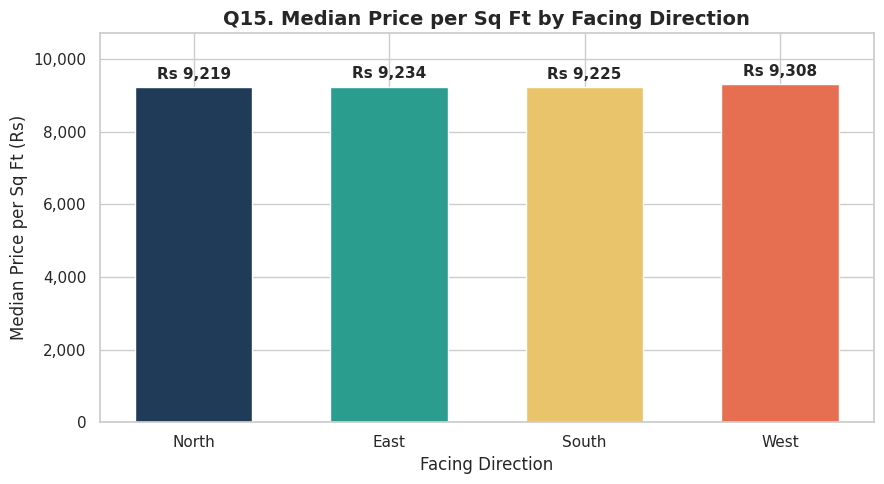

In [78]:
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(order, face["median"], color=PALETTE[:4], width=0.6)

for b, v in zip(bars, face["median"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 150, f"Rs {v:,.0f}", ha="center", va="bottom",
            fontsize=11, fontweight="bold")

ax.set_ylim(0, face["median"].max() * 1.15)
finish_chart(ax, "Q15. Median Price per Sq Ft by Facing Direction", "Facing Direction",
             "Median Price per Sq Ft (Rs)", "q15_ppsf_by_facing")

**Insight:** Facing direction has almost no effect on price per sq ft: medians range from ₹9,219 (North) to ₹9,308 (West), a gap of only 1.0% (₹89 per sq ft), with about 62,500 properties in each direction. North- and East-facing homes, traditionally preferred under Vastu, are in fact marginally the cheapest, while West-facing homes are marginally the most expensive; the means (₹13,024–₹13,140) show the same flat pattern.

**So what:** In real Indian markets, Vastu-compliant East- and North-facing homes often sell at a premium and faster; here they cost no more, so investors can buy the most sought-after directions at no extra cost, which improves resale and rental appeal.

**Action:** Prefer East- or North-facing properties when other factors are equal, show facing direction as a filter in the app for buyers who follow Vastu, and do not pay any premium for direction in this market.

### Q16. How many properties belong to each owner type?
**Chart:** Bar chart of property counts by owner type, labelled with counts and percentages. A bar chart compares group sizes more accurately than a pie chart, especially when shares are similar.

In [79]:
own = df.groupby("Owner_Type", observed=True).agg(Properties=("ID", "count"),
                                                   Good_Inv_Pct=("Good_Investment", "mean"))
own["Share_Pct"] = own["Properties"] / len(df) * 100
own["Good_Inv_Pct"] = own["Good_Inv_Pct"] * 100
own = own.sort_values("Properties", ascending=False)
print(own.round(1))

            Properties  Good_Inv_Pct  Share_Pct
Owner_Type                                     
Broker           83479         27.00      33.40
Owner            83268         27.30      33.30
Builder          83253         27.40      33.30


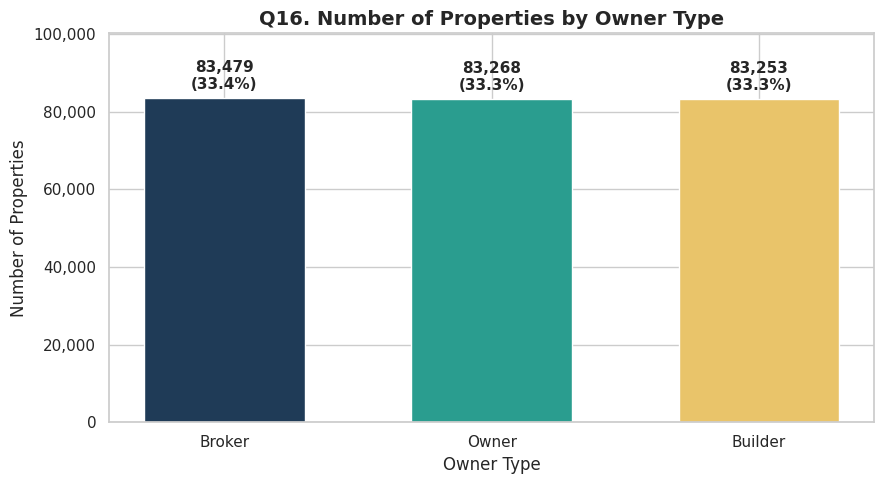

In [80]:
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(own.index.astype(str), own["Properties"], color=PALETTE[:3], width=0.6)

for b, n, p in zip(bars, own["Properties"], own["Share_Pct"]):
    ax.text(b.get_x() + b.get_width() / 2, n + 1500, f"{n:,}\n({p:.1f}%)", ha="center", va="bottom",
            fontsize=11, fontweight="bold")

ax.set_ylim(0, own["Properties"].max() * 1.2)
finish_chart(ax, "Q16. Number of Properties by Owner Type", "Owner Type",
             "Number of Properties", "q16_owner_type")

**Insight:** Properties are split almost exactly equally between brokers (83,479; 33.4%), owners (83,268; 33.3%) and builders (83,253; 33.3%). The share of Good Investments is also nearly identical across all three: 27.0% for brokers, 27.3% for owners and 27.4% for builders.

**So what:** Investors have equal access to listings through every channel, and no seller type offers better or worse deals. Since buying directly from an owner usually avoids brokerage fees (commonly 1–2% of the price, about ₹2.5–5 lakhs on an average ₹254-lakh property), owner listings deliver the same deal quality at a lower total cost.

**Action:** Prefer direct owner listings when other factors are equal, check RERA registration for builder listings, and include owner type as a filter in the app so investors can avoid brokerage costs.

### Q17. How many properties are available under each availability status?
**Chart:** Bar chart of property counts by availability status, labelled with counts and percentages, matching the Q16 format. Average price and Good Investment rate per status are also compared.

In [81]:
avail = df.groupby("Availability_Status", observed=True).agg(
    Properties=("ID", "count"), Avg_Price=("Price_in_Lakhs", "mean"),
    Median_PPSF=("Price_per_SqFt_Rs", "median"), Good_Inv_Pct=("Good_Investment", "mean"))
avail["Share_Pct"] = avail["Properties"] / len(df) * 100
avail["Good_Inv_Pct"] *= 100
avail.index = avail.index.astype(str).str.replace("_", " ")   # "Ready_to_Move" -> "Ready to Move"
print(avail.round(1))

                     Properties  Avg_Price  Median_PPSF  Good_Inv_Pct  \
Availability_Status                                                     
Ready to Move            124965     255.00     9,262.00         38.40   
Under Construction       125035     254.20     9,232.00         16.10   

                     Share_Pct  
Availability_Status             
Ready to Move            50.00  
Under Construction       50.00  


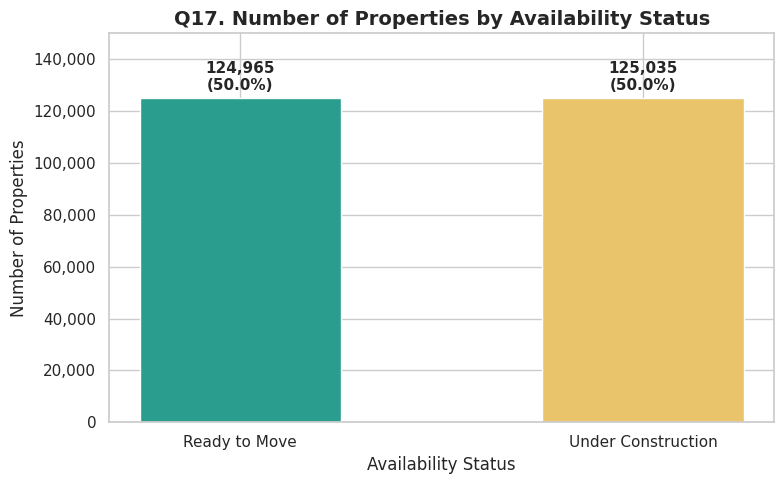

In [82]:
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(avail.index, avail["Properties"], color=[PALETTE[1], PALETTE[2]], width=0.5)

for b, n, p in zip(bars, avail["Properties"], avail["Share_Pct"]):
    ax.text(b.get_x() + b.get_width() / 2, n + 2000, f"{n:,}\n({p:.1f}%)", ha="center", va="bottom",
            fontsize=11, fontweight="bold")

ax.set_ylim(0, avail["Properties"].max() * 1.2)
finish_chart(ax, "Q17. Number of Properties by Availability Status", "Availability Status",
             "Number of Properties", "q17_availability_status")

**Insight:** Properties are split exactly evenly between ready-to-move (124,965; 50.0%) and under-construction (125,035; 50.0%). Prices are almost identical: ₹255.0 lakhs vs ₹254.2 lakhs on average, and ₹9,262 vs ₹9,232 median per sq ft (a 0.3% gap). Because readiness is one of the quality points in our rule, 38.4% of ready-to-move properties qualify as Good Investments, compared with 16.1% of under-construction ones.

**So what:** In real Indian markets, under-construction homes usually sell at a 10–20% discount to compensate for delay and builder risk; here there is no discount, so investors would carry the risk of construction delays and no rental income for no price benefit. Ready-to-move properties offer immediate rental income at the same price. The gap in Good Investment rates reflects this logic built into our rule, not a difference in the raw market data.

**Action:** Prefer ready-to-move properties in this market, only consider under-construction properties if they come with a clear price discount and RERA registration, and show availability status prominently in the app's Investment Checker reasons.

### Q18. Does parking space affect property price?
**Chart:** Box plot of total price for properties with and without parking. Parking_Space is recorded only as Yes/No (not the number of spots), so we compare the two groups. A box plot compares the full price range of both groups, not just their averages.

In [83]:
park = df.groupby("Parking_Space", observed=True).agg(
    Properties=("ID", "count"), Avg_Price=("Price_in_Lakhs", "mean"),
    Median_Price=("Price_in_Lakhs", "median"), Median_PPSF=("Price_per_SqFt_Rs", "median")).loc[["No", "Yes"]]
print(park.round(1))

diff = park.loc["Yes", "Avg_Price"] - park.loc["No", "Avg_Price"]
print(f"\nWith parking vs without: {diff:+.1f} L ({100 * diff / park.loc['No', 'Avg_Price']:+.1f}%)")

               Properties  Avg_Price  Median_Price  Median_PPSF
Parking_Space                                                  
No                 125456     254.40        253.40     9,245.50
Yes                124544     254.70        254.40     9,245.00

With parking vs without: +0.3 L (+0.1%)


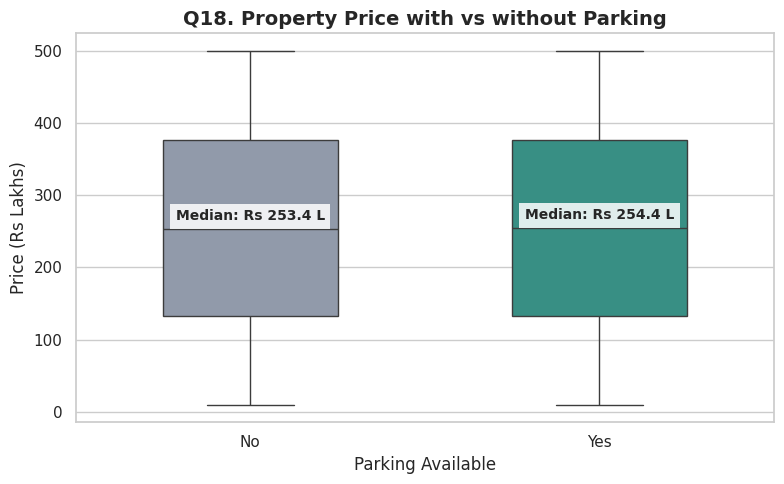

In [84]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x="Parking_Space", y="Price_in_Lakhs", order=["No", "Yes"],
            hue="Parking_Space", palette=[PALETTE[4], PALETTE[1]], legend=False, width=0.5, ax=ax)

for i, s in enumerate(["No", "Yes"]):
    m = park.loc[s, "Median_Price"]
    ax.text(i, m + 8, f"Median: Rs {m:.1f} L", ha="center", va="bottom", fontsize=10, fontweight="bold",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.85))

finish_chart(ax, "Q18. Property Price with vs without Parking", "Parking Available",
             "Price (Rs Lakhs)", "q18_parking_vs_price")

**Insight:** Parking has no effect on property price: properties with parking average ₹254.7 lakhs versus ₹254.4 lakhs without, a difference of only ₹0.3 lakhs (+0.1%). Median price per sq ft is virtually identical (₹9,245.0 with parking vs ₹9,245.5 without), and the two box plots overlap completely across the full ₹10–500 lakh range. Parking is recorded only as Yes/No, so the value of additional spots cannot be measured.

**So what:** In real Indian cities, a dedicated parking spot adds significant value (in metros it can be worth several lakhs on its own); here it comes at no extra cost, so a property with parking is simply better value and more attractive to tenants and future buyers.

**Action:** Prefer properties with parking when other factors are equal, show parking availability in the app's property details, and note in the documentation that parking is recorded only as Yes/No rather than the number of spots described in the project brief.

### Q19. How do amenities affect price per sq ft?
**Chart:** Box plot of price per sq ft by number of amenities (1–5), outliers hidden, with a median line, matching Q12–Q13. A table compares the median price per sq ft with and without each individual amenity.

In [85]:
am = df.groupby("Amenities_Count")["Price_per_SqFt_Rs"].agg(["median", "count"])
r_am = df["Amenities_Count"].corr(df["Price_per_SqFt_Rs"])
print(am.round(0).T)
print(f"\nCorrelation (r): {r_am:.3f}")

rows = []
for a in ["Gym", "Pool", "Garden", "Clubhouse", "Playground"]:
    with_a = df.loc[df[f"Has_{a}"] == 1, "Price_per_SqFt_Rs"].median()
    without = df.loc[df[f"Has_{a}"] == 0, "Price_per_SqFt_Rs"].median()
    rows.append([a, with_a, without, 100 * (with_a / without - 1)])
print("\n", pd.DataFrame(rows, columns=["Amenity", "With", "Without", "Premium_%"]).round(1).to_string(index=False))

Amenities_Count         1         2         3         4         5
median           9,240.00  9,242.00  9,207.00  9,250.00  9,294.00
count           50,106.00 49,806.00 49,862.00 50,362.00 49,864.00

Correlation (r): 0.002

    Amenity     With  Without  Premium_%
       Gym 9,269.00 9,223.00       0.50
      Pool 9,249.00 9,241.00       0.10
    Garden 9,247.00 9,242.00       0.10
 Clubhouse 9,242.00 9,250.00      -0.10
Playground 9,260.00 9,229.00       0.30


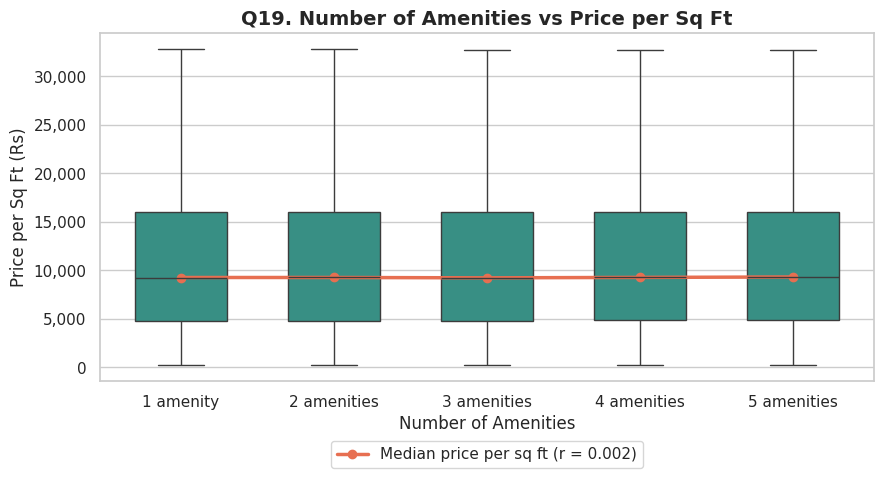

In [87]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=df, x="Amenities_Count", y="Price_per_SqFt_Rs", color=PALETTE[1], showfliers=False, width=0.6, ax=ax)
ax.plot(range(5), am["median"].values, color=PALETTE[3], marker="o", linewidth=2.5,
        label=f"Median price per sq ft (r = {r_am:.3f})")

ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15))
ax.set_xticks(range(5))
ax.set_xticklabels(["1 amenity", "2 amenities", "3 amenities", "4 amenities", "5 amenities"])
finish_chart(ax, "Q19. Number of Amenities vs Price per Sq Ft", "Number of Amenities",
             "Price per Sq Ft (Rs)", "q19_amenities_vs_ppsf")

**Insight:** Amenities have no meaningful effect on price per sq ft (r = 0.002). Median prices stay between ₹9,207 (3 amenities) and ₹9,294 (5 amenities), a gap of only 0.9%, so a property with all five amenities costs barely more per sq ft than one with a single amenity (₹9,240). No individual amenity carries a premium either: properties with a gym are 0.5% higher, a playground 0.3%, a pool or garden 0.1%, and a clubhouse 0.1% lower than those without. Each amenity count has about 50,000 properties.

**So what:** In real gated communities, amenities such as a pool or clubhouse often add 5–15% to the price; here, investors get extra amenities essentially free, which raises tenant appeal and resale value without raising the purchase price.

**Action:** Prefer amenity-rich properties (4–5 amenities) when other factors are equal, as already rewarded in the Good_Investment rule, and list each property's amenities in the app so investors can see the extra value they receive.

### Q20. How does public transport accessibility relate to price per sq ft and investment potential?
**Chart:** Two side-by-side bar charts by transport level (Low, Medium, High): median price per sq ft (left) and the share of Good Investments (right). Two panels are used because the question has two parts measured in different units.

In [88]:
tr = df.groupby("Public_Transport_Accessibility", observed=True).agg(
    Properties=("ID", "count"), Median_PPSF=("Price_per_SqFt_Rs", "median"),
    Strong_Infra_Pct=("Strong_Infra", "mean"), Good_Inv_Pct=("Good_Investment", "mean"))
tr[["Strong_Infra_Pct", "Good_Inv_Pct"]] *= 100
print(tr.round(1))
print(f"\nCorrelation transport level vs price per sq ft: r = {df['Transport_Level'].corr(df['Price_per_SqFt_Rs']):.3f}")

                                Properties  Median_PPSF  Strong_Infra_Pct  \
Public_Transport_Accessibility                                              
Low                                  83287     9,265.00              0.90   
Medium                               83008     9,269.00             15.00   
High                                 83705     9,205.00             55.00   

                                Good_Inv_Pct  
Public_Transport_Accessibility                
Low                                    22.70  
Medium                                 25.40  
High                                   33.60  

Correlation transport level vs price per sq ft: r = -0.002


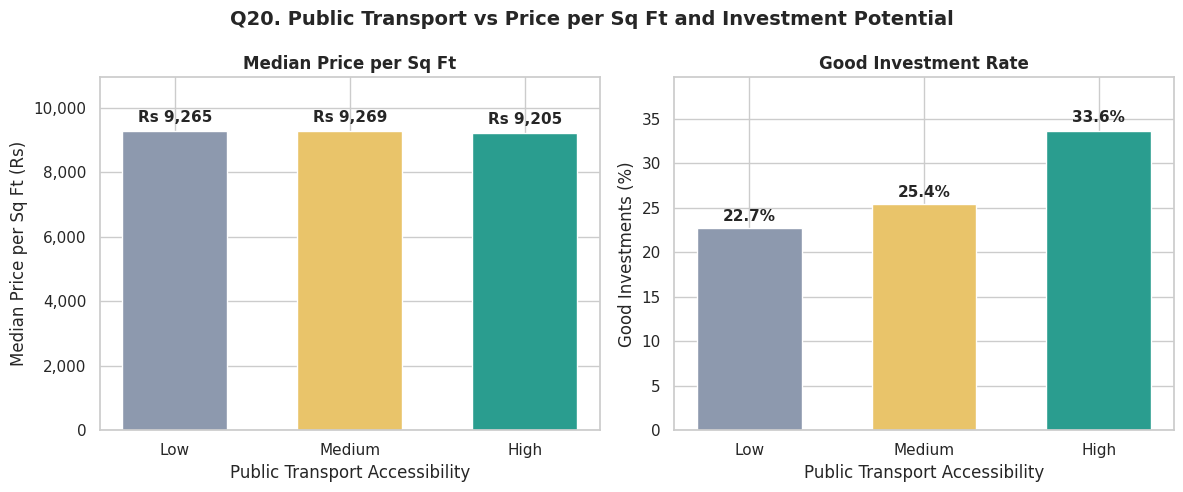

In [89]:
levels = ["Low", "Medium", "High"]
cols = [PALETTE[4], PALETTE[2], PALETTE[1]]               # slate -> gold -> teal (better access)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col, title, ylab, fmt in [
        (axes[0], "Median_PPSF", "Median Price per Sq Ft", "Median Price per Sq Ft (Rs)", "Rs {:,.0f}"),
        (axes[1], "Good_Inv_Pct", "Good Investment Rate", "Good Investments (%)", "{:.1f}%")]:
    vals = tr.loc[levels, col]
    bars = ax.bar(levels, vals, color=cols, width=0.6)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v * 1.02, fmt.format(v), ha="center", va="bottom",
                fontsize=11, fontweight="bold")
    ax.set_ylim(0, vals.max() * 1.18)
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Public Transport Accessibility")
    ax.set_ylabel(ylab)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))

fig.suptitle("Q20. Public Transport vs Price per Sq Ft and Investment Potential", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("charts/q20_transport.png", dpi=150)
plt.show()

**Insight:** Public transport access has no effect on price per sq ft (r = −0.002): median prices are ₹9,265 (Low), ₹9,269 (Medium) and ₹9,205 (High), so the best-connected properties are in fact marginally the cheapest. Investment potential, however, rises clearly with transport: 22.7% of low-access, 25.4% of medium-access and 33.6% of high-access properties qualify as Good Investments. This is because transport makes up one-third of the Infrastructure Score: 55.0% of high-access properties reach strong infrastructure (score ≥ 6.5) compared with only 0.9% of low-access ones.

**So what:** In real Indian cities, good metro and bus connectivity is one of the strongest value drivers, often adding 10–25% to prices; here investors get it at no extra cost, which makes high-transport properties the best-value segment in the dataset. The higher Good Investment rate reflects our rule rewarding infrastructure, not a market price difference.

**Action:** Prioritise properties with high public transport access, show transport level prominently in the app's Investment Checker, and highlight "High transport + below city median" listings as top opportunities.

In [90]:
from google.colab import files
!zip -r -q charts.zip charts       # bundle the charts folder into one zip; -q = quiet
files.download("charts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### EDA Summary
- **Prices, sizes and BHK are spread evenly** (uniform), and no feature affects price: size, BHK, age, location, schools, hospitals, transport, amenities, parking, furnishing and facing all show gaps of 0.1–3.3% and correlations near 0.
- **Location barely matters:** states differ by 2.5%, cities by 3.1%; Mumbai and Delhi are among the cheapest cities, which confirms the data is synthetic.
- **Price per sq ft is the real value signal:** it varies 3.3× within cities, is right-skewed, and has 19,724 outliers (7.9%), all small, expensive homes.
- **Quality comes free:** amenities, schools, hospitals, transport, parking, furnishing and preferred Vastu directions add no price premium.
- **Good Investment rule:** 27.2% qualify; it favours large homes (40.1% vs 8.9% small), ready-to-move (38.4% vs 16.1%) and high-transport properties (33.6% vs 22.7%), by design.

## Phase 6: Correlation Analysis
### 6.1 Which features are most linked to a Good Investment?
**Chart:** Horizontal bar chart of each feature's correlation with Good_Investment (1 = Yes, 0 = No), sorted. Teal bars (right) increase the chance of a Good Investment; coral bars (left) decrease it. This shows which factors drive the label and checks that the rule works as designed.

In [91]:
feat = {"Below_City_Median": "Below city median", "Price_vs_City_Median": "Price vs city median (ratio)",
        "Price_per_SqFt_Rs": "Price per sq ft", "Size_in_SqFt": "Size (sq ft)", "Price_in_Lakhs": "Price",
        "Is_Ready_To_Move": "Ready to move", "Has_Security": "Security", "Amenities_Count": "Amenities count",
        "Infrastructure_Score": "Infrastructure score", "Transport_Level": "Transport level",
        "Nearby_Schools": "Schools", "BHK": "BHK", "Age_of_Property": "Age", "Has_Parking": "Parking"}

corr_g = df[list(feat)].corrwith(df["Good_Investment"]).rename(feat).sort_values()
print(corr_g.round(3))

Price                          -0.40
Price per sq ft                -0.39
Price vs city median (ratio)   -0.39
Age                            -0.00
Parking                         0.00
BHK                             0.00
Schools                         0.07
Transport level                 0.10
Infrastructure score            0.14
Amenities count                 0.21
Ready to move                   0.25
Security                        0.25
Size (sq ft)                    0.30
Below city median               0.61
dtype: float64


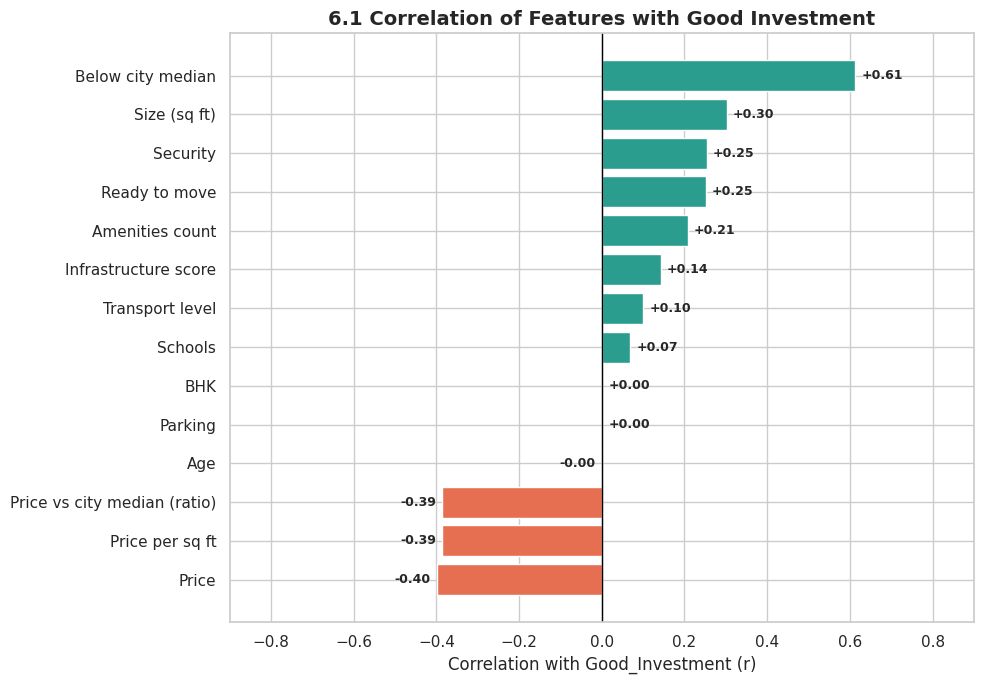

In [92]:
colors = [PALETTE[3] if v < 0 else PALETTE[1] for v in corr_g.values]

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(corr_g.index, corr_g.values, color=colors)
ax.axvline(0, color="black", linewidth=1)

for i, v in enumerate(corr_g.values):                       # label outside each bar end
    ax.text(v + (0.015 if v >= 0 else -0.015), i, f"{v:+.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=9, fontweight="bold")

ax.set_xlim(-0.9, 0.9)
finish_chart(ax, "6.1 Correlation of Features with Good Investment", "Correlation with Good_Investment (r)",
             "", "p6_1_good_investment_drivers", comma_axis=None)

**Insight:** Being priced below the city median is by far the strongest driver of a Good Investment (r = +0.61), confirming that the rule's must-have value test works as intended. Next come size (+0.30), security (+0.25), ready-to-move status (+0.25) and amenities (+0.21), followed by infrastructure score (+0.14), transport (+0.10) and schools (+0.07). Total price (−0.40), price per sq ft (−0.39) and price relative to the city median (−0.39) are negatively linked, while BHK, parking and age have no link (0.00) because they are not part of the rule.

**So what:** The typical Good Investment in this data is a large, low-priced, ready-to-move property with security and amenities, which matches sound investor logic of getting more space and quality for less money. It also means the label strongly favours bigger, cheaper homes, so investors seeking small units should review those listings separately.

**Action:** Use these drivers as the "reasons" shown in the app's Investment Checker (value first, then readiness, security, amenities and infrastructure), and state in the documentation that the label is rule-based and therefore mirrors these criteria by design.

### 6.2 Size vs investment return and infrastructure vs resale value
The project brief asks for the relationship between area and investment return, and between infrastructure score and resale value. Investment return is measured as Expected_Gain_Lakhs and resale value as Future_Price_5Y. Because a single 5% annual growth rate is applied, every property has the same percentage return (27.63%), so any differences can only come from today's price.
**Chart:** Two box plots side by side: expected 5-year gain by size band (left) and estimated 5-year value by infrastructure band (right).

In [93]:
infra_band = pd.cut(df["Infrastructure_Score"], bins=[0, 3.5, 6.5, 10.01], right=False,
                    labels=["Low (0–3.5)", "Medium (3.5–6.5)", "High (6.5–10)"])
d = df.assign(Infra_Band=infra_band)

ret_pct = (df["Future_Price_5Y"] / df["Price_in_Lakhs"] - 1) * 100
print(f"5-year return %: min {ret_pct.min():.2f} | max {ret_pct.max():.2f}")
print(f"Size vs expected gain:        r = {df['Size_in_SqFt'].corr(df['Expected_Gain_Lakhs']):.3f}")
print(f"Infrastructure vs future price: r = {df['Infrastructure_Score'].corr(df['Future_Price_5Y']):.3f}")

print("\n", d.groupby("Size_Band", observed=True)["Expected_Gain_Lakhs"].median().round(1))
print("\n", d.groupby("Infra_Band", observed=True)["Future_Price_5Y"].agg(["median", "count"]).round(1))

5-year return %: min 27.58 | max 27.68
Size vs expected gain:        r = -0.003
Infrastructure vs future price: r = -0.001

 Size_Band
Small    70.80
Medium   70.10
Large    69.80
Name: Expected_Gain_Lakhs, dtype: float64

                   median   count
Infra_Band                      
Low (0–3.5)       323.80   59213
Medium (3.5–6.5)  324.30  131509
High (6.5–10)     323.50   59278


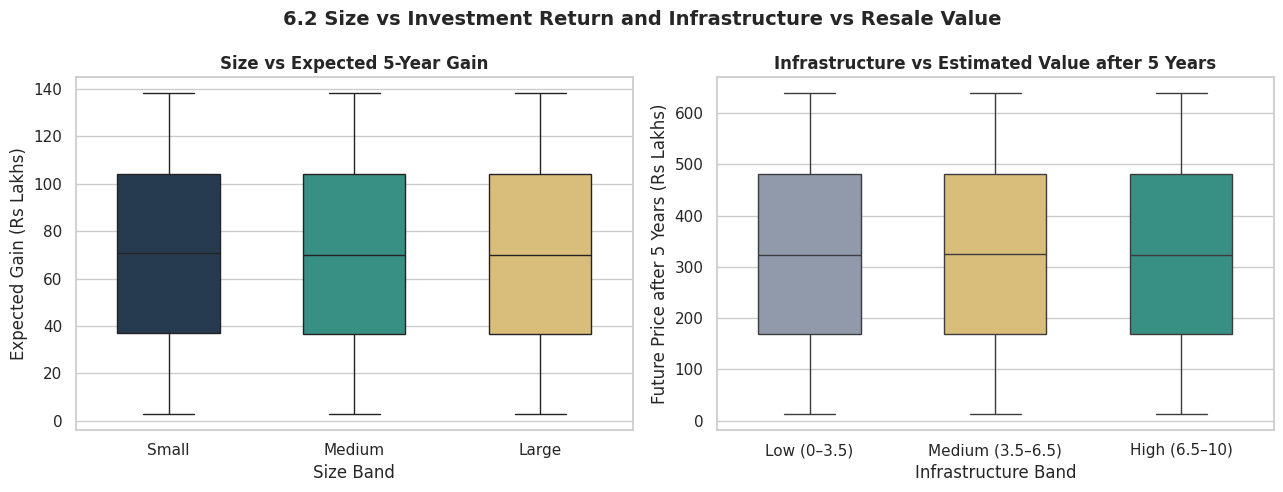

In [94]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(data=d, x="Size_Band", y="Expected_Gain_Lakhs", hue="Size_Band",
            palette=PALETTE[:3], legend=False, width=0.55, ax=axes[0])
axes[0].set_title("Size vs Expected 5-Year Gain", fontweight="bold")
axes[0].set_xlabel("Size Band")
axes[0].set_ylabel("Expected Gain (Rs Lakhs)")

sns.boxplot(data=d, x="Infra_Band", y="Future_Price_5Y", hue="Infra_Band",
            palette=[PALETTE[4], PALETTE[2], PALETTE[1]], legend=False, width=0.55, ax=axes[1])
axes[1].set_title("Infrastructure vs Estimated Value after 5 Years", fontweight="bold")
axes[1].set_xlabel("Infrastructure Band")
axes[1].set_ylabel("Future Price after 5 Years (Rs Lakhs)")

fig.suptitle("6.2 Size vs Investment Return and Infrastructure vs Resale Value", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("charts/p6_2_size_infra_vs_value.png", dpi=150)
plt.show()

**Insight:** Neither size nor infrastructure affects investment return or resale value. Every property earns the same 5-year return of about 27.6% (27.58%–27.68%, differing only through rounding), because a single 5% annual growth rate is applied. In rupee terms, median expected gain is almost identical for small (₹70.8 lakhs), medium (₹70.1 lakhs) and large homes (₹69.8 lakhs), with no correlation between size and gain (r = −0.003). Estimated value after 5 years is also flat across infrastructure bands: ₹323.8 lakhs (low), ₹324.3 lakhs (medium) and ₹323.5 lakhs (high), with r = −0.001.

**So what:** Under a fixed growth assumption, future value depends only on today's price, and since today's price is unrelated to size or infrastructure in this data, these factors cannot predict returns. In a real market, well-connected areas and larger homes often appreciate differently, so this is a limitation of both the synthetic data and the fixed-rate method. The dataset has no crime-rate column, so the brief's question on crime and investment cannot be analysed.

**Action:** Present Future_Price_5Y in the app as an estimate based on a stated 5% assumption, judge investment quality through the Good_Investment rule rather than predicted returns, and recommend location- or feature-based growth rates as a future improvement if real historical price data becomes available.

## Phase 7: Save the Cleaned Dataset
### 7.1 Final column selection
We drop the rounded Price_per_SqFt (replaced by Price_per_SqFt_Rs) and the Amenities text (replaced by Amenities_Count and five flags). All other original and engineered columns are kept for the app and documentation.

In [95]:
df_clean = df.drop(columns=["Price_per_SqFt", "Amenities"])
print("Final shape:", df_clean.shape)

Final shape: (250000, 49)


### 7.2 Saving the cleaned data
The cleaned data is saved as a standard CSV (submission deliverable) and as a compressed .csv.gz copy for the Streamlit app.

In [97]:
df_clean.to_csv("india_housing_cleaned.csv", index=False)                         # index=False: don't save row numbers
df_clean.to_csv("india_housing_cleaned.csv.gz", index=False, compression="gzip")  # compressed copy for the app

In [98]:
for f in ["india_housing_cleaned.csv", "india_housing_cleaned.csv.gz"]:
    print(f"{f}: {os.path.getsize(f) / 1024**2:.1f} MB")

check = pd.read_csv("india_housing_cleaned.csv.gz")
print("\nReloaded shape:", check.shape)
print("Missing values:", check.isnull().sum().sum())
print("Good investments:", check["Good_Investment"].sum())

india_housing_cleaned.csv: 58.5 MB
india_housing_cleaned.csv.gz: 12.6 MB

Reloaded shape: (250000, 49)
Missing values: 0
Good investments: 68122


In [99]:
files.download("india_housing_cleaned.csv.gz")
files.download("india_housing_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>